# 04 — Generador condicional por Flow Matching (CFM)

**Proyecto Final — Inteligencia Artificial II (UNCuyo)**  
**Alumno:** Enzo Palau (Legajo 13686)

## Objetivo

Entrenar un **Flow Matching condicional** que transforme ruido gaussiano en un espectrograma mel `128×128` de una nota, a partir de:

- familia de instrumento (`brass`, `guitar`, `keyboard`, `string`);
- pitch MIDI (36–84).

Es el segundo generador del proyecto y el rival directo del C-VAE del NB03. El juez AST **no se usa acá**: las muestras se guardan en `muestras_cfm.npz` para el torneo del NB05. Acá usamos `train` para entrenar y `valid` para early stopping, métricas y ejemplos de escucha; `test` queda reservado.

## Qué cambia respecto del NB03

| | NB03 (C-VAE) | NB04 (Flow Matching) |
|---|---|---|
| Objetivo | `L1 + β·KL` sobre una reconstrucción | `MSE` sobre el campo de velocidades |
| Representación | latente de 128 dims (16 activas) | no hay latente: se integra una ODE |
| Muestreo | un `forward` del decoder | 50 pasos de Euler |
| Ventaja esperada | reconstrucción fiel | muestras nítidas, sin promediar |

La comparación es justa porque los dos modelos ven el mismo `train`, comparten el mismo condicionamiento y generan sobre las mismas 20 condiciones `(familia, pitch)`.

## Qué se va a producir

1. Un UNet condicional entrenado con curvas de pérdida y checkpoints.
2. 80 muestras generadas (4 familias × 5 pitches × 4 semillas) en `muestras_cfm.npz`.
3. Métricas objetivas sin juez: error de pitch, diversidad, FID-lite y comparación contra el VAE y el baseline de media.
4. Estudio de pasos de integración (10/25/50/100).
5. Ejemplos de escucha con Griffin-Lim (real vs generado) y trayectorias de la ODE.

## 1. Configuración del entorno

### ¿Qué se hace a continuación?
Se importan las librerías, se fijan las semillas (`SEED=42`) y se detectan las rutas de datos y salida para Kaggle, Colab o local. En Kaggle se buscan los `.npz` en `/kaggle/input` y se escribe en `/kaggle/working/cfm_output`.

### ¿Por qué se hace?
El notebook tiene que correr sin cambios en Kaggle y, eventualmente, en local. Fijar la semilla hace reproducibles los batches y las muestras. La detección robusta de rutas evita el error más común al importar un notebook: que el dataset esté montado con otro nombre o un nivel de carpeta más adentro.

In [1]:
import os
import sys
import json
import math
import time
import random
import warnings
import zipfile
import shutil
import traceback
from pathlib import Path
from copy import deepcopy

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader

import librosa
import soundfile as sf
import IPython.display as ipd

warnings.filterwarnings('ignore')

# ── Semilla global ──────────────────────────────────────────────────────────
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = False
torch.backends.cudnn.benchmark = True

# ── Detección de entorno ────────────────────────────────────────────────────
IN_KAGGLE = os.environ.get('KAGGLE_KERNEL_RUN_TYPE') is not None
IN_COLAB = 'google.colab' in sys.modules


def _encontrar_data_dir():
    '''Busca la carpeta que contiene los .npz procesados.'''
    candidatos = [
        Path('/kaggle/input/nsynth-processed-palau'),
        Path('/kaggle/input/datasets/enzopalau/nsynth-processed-palau'),
        Path('/kaggle/input/nsynth-processed'),
        Path('/content/drive/MyDrive/IA2_Proyecto_Instrumentos/processed'),
        Path('./data_processed/processed'),
        Path('../tensores'),
        Path('../../tensores'),
        Path('./tensores'),
    ]
    for p in candidatos:
        if p.exists() and any(p.glob('*.npz')):
            return p
    raiz = Path('/kaggle/input')
    if raiz.exists():
        matches = list(raiz.rglob('nsynth_processed_train.npz'))
        if matches:
            return matches[0].parent
    return Path('./data_processed/processed')


DATA_DIR = _encontrar_data_dir()

if IN_KAGGLE:
    OUTPUT_DIR = Path('/kaggle/working/cfm_output')
elif IN_COLAB:
    OUTPUT_DIR = Path('/content/cfm_output')
else:
    OUTPUT_DIR = Path('./cfm_output')

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
AUDIO_DIR = OUTPUT_DIR / 'audio'
AUDIO_DIR.mkdir(parents=True, exist_ok=True)

print(f'[INFO] Entorno: {"Kaggle" if IN_KAGGLE else ("Colab" if IN_COLAB else "local")}')
print(f'[INFO] DATA_DIR   = {DATA_DIR}')
print(f'[INFO] OUTPUT_DIR = {OUTPUT_DIR}')
print(f'[INFO] Semilla    = {SEED}')

[INFO] Entorno: Kaggle
[INFO] DATA_DIR   = /kaggle/input/datasets/enzopalau/nsynth-processed-palau
[INFO] OUTPUT_DIR = /kaggle/working/cfm_output
[INFO] Semilla    = 42


## 2. Hardware, constantes y carga de datos

### ¿Qué se hace a continuación?
Se detecta la GPU, se definen las constantes del problema y se cargan los splits `train` y `valid` desde los `.npz`. Antes de seguir se verifican shapes, dtypes, rangos, familias y ausencia de NaN/Inf.

### ¿Por qué se hace?
Entrenar 45 minutos para descubrir que un tensor tenía otra forma o un valor corrupto es exactamente lo que queremos evitar. Esta verificación cuesta segundos y deja el terreno limpio. El split `test` no se carga: se reserva para la evaluación final con el juez.

In [2]:
# ── Dispositivo ─────────────────────────────────────────────────────────────
if torch.cuda.is_available():
    device = torch.device('cuda:0')
    print(f'[INFO] GPU: {torch.cuda.get_device_name(0)}')
    print(f'[INFO] GPUs visibles: {torch.cuda.device_count()}')
    print(f'[INFO] VRAM: {torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB')
else:
    device = torch.device('cpu')
    print('[ADVERTENCIA] No hay GPU. Se usará CPU (mucho más lento).')

use_amp = (device.type == 'cuda')
print(f'[INFO] Dispositivo: {device} | AMP: {use_amp}')

# ── Constantes del problema ─────────────────────────────────────────────────
FAMILY_NAMES = ['brass', 'guitar', 'keyboard', 'string']
NUM_FAMILIES = len(FAMILY_NAMES)
PITCH_MIN = 36
PITCH_MAX = 84
NUM_PITCHES = PITCH_MAX - PITCH_MIN + 1
IMG_SIZE = 128


# ── Carga robusta de un split ───────────────────────────────────────────────
def cargar_split(nombre_split):
    alias = {'val': 'valid'}
    split_real = alias.get(nombre_split, nombre_split)
    candidatos = [
        DATA_DIR / f'nsynth_processed_{split_real}.npz',
        DATA_DIR / f'nsynth_processed_{nombre_split}.npz',
        DATA_DIR / f'{split_real}.npz',
        DATA_DIR / f'{nombre_split}.npz',
    ]
    ruta = next((p for p in candidatos if p.exists()), None)
    if ruta is None:
        matches = list(DATA_DIR.rglob(f'nsynth_processed_{split_real}.npz'))
        ruta = matches[0] if matches else None
    if ruta is None:
        raise FileNotFoundError(
            f'No se encontró el split "{nombre_split}" en {DATA_DIR}. '
            f'Archivos .npz presentes: {[p.name for p in DATA_DIR.glob("*.npz")]}'
        )

    datos = np.load(ruta)
    mels = datos['mels'].astype(np.float32)
    families = datos['families'].astype(np.int64)
    pitches = datos['pitches'].astype(np.int64)

    if mels.ndim == 3:
        mels = mels[:, None, :, :]
    assert mels.shape[1:] == (1, IMG_SIZE, IMG_SIZE), f'Shape inesperada: {mels.shape}'
    assert np.isfinite(mels).all(), 'Hay NaN/Inf en los espectrogramas'
    assert families.min() >= 0 and families.max() < NUM_FAMILIES
    assert pitches.min() >= PITCH_MIN and pitches.max() <= PITCH_MAX

    X = torch.from_numpy(mels)
    y = torch.from_numpy(families)
    p = torch.from_numpy(pitches)
    print(f'[INFO] {nombre_split:5s} -> {ruta.name} | X={tuple(X.shape)} | '
          f'familias={np.bincount(families, minlength=NUM_FAMILIES).tolist()} | '
          f'rango=[{mels.min():.3f}, {mels.max():.3f}]')
    return X, y, p, ruta


X_train, y_train, p_train, ruta_train = cargar_split('train')
X_val, y_val, p_val, ruta_val = cargar_split('valid')

# test NO se carga: queda reservado para el notebook de evaluación final.
print('[INFO] test reservado para el torneo del NB05 (no se toca acá).')

assert len(X_train) > 0 and len(X_val) > 0
assert set(y_train.unique().tolist()) == set(range(NUM_FAMILIES))
assert set(y_val.unique().tolist()) == set(range(NUM_FAMILIES))
print('[OK] Verificación previa completada.')

[INFO] GPU: Tesla T4
[INFO] GPUs visibles: 2
[INFO] VRAM: 15.6 GB
[INFO] Dispositivo: cuda:0 | AMP: True
[INFO] train -> nsynth_processed_train.npz | X=(18000, 1, 128, 128) | familias=[4500, 4500, 4500, 4500] | rango=[-1.000, 1.000]
[INFO] valid -> nsynth_processed_valid.npz | X=(2297, 1, 128, 128) | familias=[704, 827, 170, 596] | rango=[-1.000, 1.000]
[INFO] test reservado para el torneo del NB05 (no se toca acá).
[OK] Verificación previa completada.


## 3. Normalización del mel y DataLoaders

### ¿Qué se hace a continuación?
Se calculan la media y el desvío globales de `train`, se define `normalizar`/`desnormalizar` y se crean los `DataLoader`. Cada muestra devuelve `(mel, familia, pitch)` con el mel **estandarizado** (media 0, desvío 1).

### ¿Por qué se hace?
El CFM arranca desde `x0 ~ N(0, I)`. Si los datos viven en `[-1, 1]` con media −0.79 y desvío 0.36, la trayectoria recta entre el ruido y el dato tiene un corrimiento grande y el modelo gasta capacidad aprendiendo ese offset. Estandarizar con las estadísticas de `train` deja el prior y los datos en la misma escala, que es la condición para la que está pensado el camino recto. La desnormalización se aplica al final del muestreo, así que todas las métricas y el audio siguen en la escala original `[-1, 1]` y son comparables con el NB03.

In [3]:
BATCH_SIZE = 64

# ── Estadísticas de train (los únicos datos que se usan para normalizar) ───
DATA_MEAN = float(X_train.mean().item())
DATA_STD = float(X_train.std().item())
print(f'[INFO] Estadísticas TRAIN: media={DATA_MEAN:.4f} | desvío={DATA_STD:.4f}')

def normalizar(x):
    return (x - DATA_MEAN) / DATA_STD

def desnormalizar(x):
    return x * DATA_STD + DATA_MEAN

# Control de ida y vuelta
_x = X_train[:2]
assert torch.allclose(desnormalizar(normalizar(_x)), _x, atol=1e-5)
print('[OK] Normalización invertible.')

ds_train = TensorDataset(X_train, y_train, p_train)
ds_val = TensorDataset(X_val, y_val, p_val)

loader_train = DataLoader(
    ds_train, batch_size=BATCH_SIZE, shuffle=True,
    drop_last=True, num_workers=0, pin_memory=use_amp,
)
loader_val = DataLoader(
    ds_val, batch_size=BATCH_SIZE, shuffle=False,
    drop_last=False, num_workers=0, pin_memory=use_amp,
)

print(f'[INFO] Batches train: {len(loader_train)} | Batches valid: {len(loader_val)}')
xb, fb, pb = next(iter(loader_train))
print(f'[INFO] Batch ejemplo: x={tuple(xb.shape)} | family={tuple(fb.shape)} | pitch={tuple(pb.shape)}')
print(f'[INFO] Mel normalizado: media={normalizar(xb).mean():.3f} | desvío={normalizar(xb).std():.3f}')

[INFO] Estadísticas TRAIN: media=-0.6325 | desvío=0.4987
[OK] Normalización invertible.
[INFO] Batches train: 281 | Batches valid: 36
[INFO] Batch ejemplo: x=(64, 1, 128, 128) | family=(64,) | pitch=(64,)
[INFO] Mel normalizado: media=0.134 | desvío=1.031


## 4. Arquitectura: UNet condicional con tiempo y FiLM

### ¿Qué se hace a continuación?
Se define la red que aproxima el campo de velocidades `v(x_t, t, familia, pitch)`:

- **Embedding de tiempo** sinusoidal (128) + MLP, como en los modelos de difusión.
- **Embedding de condición**: familia (32) + pitch (32) → MLP a 256; se suma al embedding de tiempo.
- **UNet** con canales `32/64/128/256` y dos `ResBlock` por nivel. Cada `ResBlock` modula sus features con FiLM a partir del embedding combinado `(tiempo + condición)`.
- **Bottleneck** en `8×8` con self-attention de 4 cabezas (solo 64 tokens: barato).
- **Skip connections** entre encoder y decoder, salida de 1 canal lineal (una velocidad puede ser cualquier real, no se satura con `tanh`).

### ¿Por qué se hace?
El UNet es el estándar para generar imágenes y espectrogramas: combina contexto global (el bottleneck ve toda la imagen) con detalle local (los skips conservan los armónicos finos). FiLM inyecta la condición en todas las escalas sin multiplicar parámetros. La atención en el bottleneck permite que bins alejados se coordinen, que es justo lo que necesita un espectro armónico. La última convolución de cada bloque se inicializa en cero: así el UNet arranca como una identidad y el entrenamiento es estable desde el primer paso.

In [4]:
# ── Hiperparámetros de arquitectura ─────────────────────────────────────────
BASE_CH = 24
COND_DIM = 64
EMB_DIM = 256
MULT = (1, 2, 4, 8)


class SinusoidalTime(nn.Module):
    '''Embedding sinusoidal del tiempo continuo t ∈ [0, 1].'''

    def __init__(self, dim=128):
        super().__init__()
        self.dim = dim

    def forward(self, t):
        half = self.dim // 2
        freqs = torch.exp(
            -math.log(10000.0) * torch.arange(half, device=t.device, dtype=torch.float32) / half
        )
        args = t.float()[:, None] * freqs[None, :]
        return torch.cat([torch.sin(args), torch.cos(args)], dim=-1)


class CondEmbed(nn.Module):
    '''Condición discreta (familia + altura) a un vector de EMB_DIM.'''

    def __init__(self, emb_dim=EMB_DIM, fam_dim=32, pitch_dim=32):
        super().__init__()
        self.family_emb = nn.Embedding(NUM_FAMILIES, fam_dim)
        self.pitch_emb = nn.Embedding(NUM_PITCHES, pitch_dim)
        self.mlp = nn.Sequential(
            nn.Linear(fam_dim + pitch_dim, emb_dim), nn.SiLU(),
            nn.Linear(emb_dim, emb_dim),
        )

    def forward(self, family, pitch):
        p = (pitch - PITCH_MIN).clamp(0, NUM_PITCHES - 1)
        c = torch.cat([self.family_emb(family), self.pitch_emb(p)], dim=1)
        return self.mlp(c)


class ResBlock(nn.Module):
    '''Conv 3×3 + GroupNorm + FiLM, con conexión residual.'''

    def __init__(self, in_ch, out_ch, emb_dim, groups=8):
        super().__init__()
        self.norm1 = nn.GroupNorm(groups, in_ch)
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, padding=1)
        self.emb = nn.Linear(emb_dim, out_ch * 2)
        self.norm2 = nn.GroupNorm(groups, out_ch)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, padding=1)
        self.skip = nn.Conv2d(in_ch, out_ch, 1) if in_ch != out_ch else nn.Identity()
        nn.init.zeros_(self.conv2.weight)
        nn.init.zeros_(self.conv2.bias)

    def forward(self, x, emb):
        h = self.conv1(F.silu(self.norm1(x)))
        scale, shift = self.emb(F.silu(emb)).chunk(2, dim=1)
        h = h * (1.0 + scale[:, :, None, None]) + shift[:, :, None, None]
        h = self.conv2(F.silu(self.norm2(h)))
        return h + self.skip(x)


class SelfAttention(nn.Module):
    '''Atención global sobre el mapa de features (bottleneck 8×8).'''

    def __init__(self, ch, heads=4, groups=8):
        super().__init__()
        self.norm = nn.GroupNorm(groups, ch)
        self.qkv = nn.Conv2d(ch, ch * 3, 1)
        self.proj = nn.Conv2d(ch, ch, 1)
        self.heads = heads
        nn.init.zeros_(self.proj.weight)
        nn.init.zeros_(self.proj.bias)

    def forward(self, x):
        B, C, H, W = x.shape
        h = self.norm(x)
        q, k, v = self.qkv(h).reshape(B, 3, self.heads, C // self.heads, H * W).unbind(1)
        attn = torch.softmax(q.transpose(-1, -2) @ k / math.sqrt(C / self.heads), dim=-1)
        out = (attn @ v.transpose(-1, -2)).transpose(-1, -2).reshape(B, C, H, W)
        return x + self.proj(out)


class CondCFMUNet(nn.Module):
    '''UNet que predice la velocidad v = x1 − x0 del camino recto.'''

    def __init__(self, in_ch=1, base_ch=BASE_CH, mult=MULT,
                 emb_dim=EMB_DIM, cond_dim=COND_DIM):
        super().__init__()
        chs = [base_ch * m for m in mult]
        self.n_levels = len(chs)
        self.time_embed = nn.Sequential(
            SinusoidalTime(emb_dim), nn.Linear(emb_dim, emb_dim), nn.SiLU(),
            nn.Linear(emb_dim, emb_dim),
        )
        self.cond_embed = CondEmbed(emb_dim)
        self.in_conv = nn.Conv2d(in_ch, chs[0], 3, padding=1)

        self.enc = nn.ModuleList()
        prev = chs[0]
        for ch in chs:
            self.enc.append(nn.ModuleList([
                ResBlock(prev, ch, emb_dim), ResBlock(ch, ch, emb_dim),
            ]))
            prev = ch

        self.downs = nn.ModuleList([
            nn.Conv2d(chs[i], chs[i], 3, stride=2, padding=1)
            for i in range(self.n_levels)
        ])

        self.mid = nn.ModuleList([
            ResBlock(chs[-1], chs[-1], emb_dim),
            SelfAttention(chs[-1], heads=4),
            ResBlock(chs[-1], chs[-1], emb_dim),
        ])

        self.ups = nn.ModuleList()
        self.dec = nn.ModuleList()
        up_in = chs[-1]
        for i in reversed(range(self.n_levels)):
            self.ups.append(nn.ConvTranspose2d(up_in, chs[i], 2, stride=2))
            self.dec.append(nn.ModuleList([
                ResBlock(chs[i] * 2, chs[i], emb_dim), ResBlock(chs[i], chs[i], emb_dim),
            ]))
            up_in = chs[i]

        self.out_norm = nn.GroupNorm(8, chs[0])
        self.out_conv = nn.Conv2d(chs[0], in_ch, 3, padding=1)

    def forward(self, x, t, family, pitch):
        emb = self.time_embed(t) + self.cond_embed(family, pitch)
        h = self.in_conv(x)
        skips = []
        for i, blocks in enumerate(self.enc):
            for blk in blocks:
                h = blk(h, emb)
            skips.append(h)
            if i < self.n_levels - 1:
                h = self.downs[i](h)
            else:
                h = self.downs[i](h)   # bottleneck 8×8
        h = self.mid[0](h, emb)
        h = self.mid[1](h)
        h = self.mid[2](h, emb)
        # ups/dec se guardaron en orden de decoder (0 = nivel más profundo)
        for j, i in enumerate(reversed(range(self.n_levels))):
            h = self.ups[j](h)
            h = torch.cat([h, skips[i]], dim=1)
            for blk in self.dec[j]:
                h = blk(h, emb)
        return self.out_conv(F.silu(self.out_norm(h)))


model_test = CondCFMUNet().to(device)
n_params = sum(p.numel() for p in model_test.parameters() if p.requires_grad)
print(f'[INFO] CondCFMUNet — parámetros entrenables: {n_params:,} ({n_params/1e6:.2f} M)')

with torch.no_grad():
    dummy = torch.randn(2, 1, IMG_SIZE, IMG_SIZE, device=device)
    t_d = torch.rand(2, device=device)
    fam_d = torch.tensor([0, 1], device=device)
    pit_d = torch.tensor([60, 72], device=device)
    out_d = model_test(dummy, t_d, fam_d, pit_d)
print(f'[INFO] Salida: {tuple(out_d.shape)} | igual al input: {out_d.shape == dummy.shape}')
assert out_d.shape == dummy.shape
del model_test, dummy, t_d, fam_d, pit_d, out_d
torch.cuda.empty_cache()

[INFO] CondCFMUNet — parámetros entrenables: 7,197,217 (7.20 M)
[INFO] Salida: (2, 1, 128, 128) | igual al input: True


## 5. Entrenamiento: hiperparámetros, EMA, checkpoints y vocoder

### ¿Qué se hace a continuación?
Se fijan los hiperparámetros del entrenamiento, se define el promedio móvil exponencial de pesos (EMA), las funciones de guardado/carga atómica de checkpoints y el vocoder Griffin-Lim.

### ¿Por qué se hace?
El EMA promedia los pesos de las últimas miles de iteraciones y reduce el ruido de alta frecuencia que deja el muestreo de una ODE; en modelos de difusión suele ser la diferencia entre una muestra limpia y una con grano. Es casi gratis: un tensor extra del tamaño del modelo y una operación por paso.

El guardado atómico evita checkpoints corruptos si Kaggle corta la sesión justo mientras escribe. El vocoder es el mismo del NB03, ya corregido: invierte `(dB + 40) / 40`, usa la escala mel del análisis (`htk=True, norm=None`), aplica compuerta suave, fade y una única normalización. Que sea idéntico es importante: así los audios de este notebook se pueden comparar con los del VAE sin que el vocoder introduzca diferencias.

In [5]:
# ── Entrenamiento ───────────────────────────────────────────────────────────
LR = 2e-4
WEIGHT_DECAY = 0.01
# 80 epochs y paciencia 15: los mismos valores que el VAE (NB03), para que la
# comparación del informe sea por cantidad de pasadas sobre los datos. Ojo: acá
# una época cuesta ~2 min (el UNet corre a 128×128 en cada nivel), así que 80
# epochs son ~2 h 35 de GPU en total: se llega con dos sesiones y la reanudación.
EPOCHS = 80
WARMUP_EPOCHS = 3
PATIENCE = 15
GRAD_CLIP = 1.0
EMA_DECAY = 0.999
MAX_TRAIN_MINUTES = 68  # + ~7 min de métricas/audios = ~75 min por sesión
RESUME = True
# Si el modelo ya está entrenado y solo se quieren recalcular métricas, figuras
# y audios (por ejemplo para recuperar la tabla de duración sin volver a
# entrenar), poner True: se saltea el bucle y se evalúa cfm_best.pt.
SOLO_EVALUAR = True

# ── Muestreo ────────────────────────────────────────────────────────────────
EULER_STEPS = 50
GEN_PITCHES = [36, 48, 60, 72, 84]
GEN_SEEDS = [42, 43, 44, 45]
LISTEN_PITCH = 70

# ── Audio ───────────────────────────────────────────────────────────────────
SR = 16000
N_FFT = 2048
HOP = 500
N_MELS = 128
GATE_DB = -40.0
FADE_MS = 15


class EMA:
    '''Promedio móvil exponencial de los pesos.'''

    def __init__(self, model, decay=EMA_DECAY):
        self.decay = decay
        self.shadow = {
            k: v.detach().clone().float()
            for k, v in model.state_dict().items() if v.is_floating_point()
        }
        self.n_updates = 0

    @torch.no_grad()
    def update(self, model):
        self.n_updates += 1
        # calentamiento: al principio copia casi el peso actual
        d = min(self.decay, (1.0 + self.n_updates) / (10.0 + self.n_updates))
        for k, v in model.state_dict().items():
            if k in self.shadow:
                self.shadow[k].mul_(d).add_(v.detach().float(), alpha=1.0 - d)

    @torch.no_grad()
    def apply_to(self, model):
        state = model.state_dict()
        for k, v in self.shadow.items():
            if k in state:
                state[k].copy_(v.to(dtype=state[k].dtype, device=state[k].device))


def guardar_checkpoint(path, payload):
    tmp = path.with_suffix(path.suffix + '.tmp')
    torch.save(payload, tmp)
    os.replace(tmp, path)


def cargar_checkpoint(path, dev):
    try:
        return torch.load(path, map_location=dev, weights_only=False)
    except TypeError:
        return torch.load(path, map_location=dev)


class GriffinLimVocoder:
    '''Invierte mel [-1, 1] a audio (idéntico al NB03 corregido).'''

    def __init__(self, sample_rate=SR, n_fft=N_FFT, hop_length=HOP, n_mels=N_MELS):
        self.sample_rate = sample_rate
        self.n_fft = n_fft
        self.hop_length = hop_length
        self.n_mels = n_mels

    @staticmethod
    def _compuerta_suave(wav, sr, umbral_db=-40.0, rodilla_db=8.0, suav_ms=30):
        win = max(1, int(sr * 0.02))  # 20 ms
        if len(wav) < win:
            return wav
        env = np.sqrt(np.convolve(wav ** 2, np.ones(win) / win, mode='same'))
        ref = max(float(env.max()), 1e-12)
        db = 20.0 * np.log10(env / ref + 1e-12)
        gan = np.clip((db - (umbral_db - rodilla_db)) / rodilla_db, 0.0, 1.0)
        k = max(1, int(sr * suav_ms / 1000))
        gan = np.convolve(gan, np.ones(k) / k, mode='same')
        return (wav * gan).astype(np.float32)

    def mel_norm_to_audio(self, mel_norm, n_iter=250, gate_db=GATE_DB, fade_ms=FADE_MS):
        mel = np.asarray(mel_norm, dtype=np.float32)
        mel_power = librosa.db_to_power(mel * 40.0 - 40.0, ref=1.0)
        wav = librosa.feature.inverse.mel_to_audio(
            mel_power,
            sr=self.sample_rate,
            n_fft=self.n_fft,
            win_length=self.n_fft,
            hop_length=self.hop_length,
            power=2.0,
            n_iter=n_iter,
            htk=True,
            norm=None,
        )
        wav = np.asarray(wav, dtype=np.float32)
        if wav.size == 0:
            return wav

        # Griffin-Lim con center=True devuelve (n_frames - 1) * hop muestras;
        # lo llevamos exactamente a 128 * hop = 64.000 muestras (4 s a 16 kHz).
        objetivo = int(mel.shape[1] * self.hop_length)
        if wav.size < objetivo:
            wav = np.pad(wav, (0, objetivo - wav.size))
        else:
            wav = wav[:objetivo]

        wav = wav - float(wav.mean())
        if gate_db is not None:
            wav = self._compuerta_suave(wav, self.sample_rate, umbral_db=gate_db)

        nf = int(self.sample_rate * fade_ms / 1000)
        if nf > 0 and len(wav) > 2 * nf:
            wav[:nf] *= np.linspace(0.0, 1.0, nf, dtype=np.float32)
            wav[-nf:] *= np.linspace(1.0, 0.0, nf, dtype=np.float32)

        pico = float(np.max(np.abs(wav)))
        if pico > 1e-7:
            wav = wav / pico * 0.95
        return wav.astype(np.float32)


def to_py(obj):
    '''Convierte tipos numpy/torch a tipos serializables en JSON.'''
    if isinstance(obj, dict):
        return {str(k): to_py(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple)):
        return [to_py(v) for v in obj]
    if isinstance(obj, float) and not math.isfinite(obj):
        return None
    if isinstance(obj, (np.floating, np.integer)):
        return obj.item()
    if isinstance(obj, np.ndarray):
        return obj.tolist()
    if isinstance(obj, torch.Tensor):
        return obj.detach().cpu().tolist()
    return obj


vocoder = GriffinLimVocoder()
print('[INFO] Vocoder Griffin-Lim listo.')
print(f'[INFO] n_fft={N_FFT} | hop={HOP} | mel HTK norm=None | '
      f'gate={GATE_DB} dB | fade={FADE_MS} ms | normalización única a 0.95')
print(f'[INFO] Config: base_ch={BASE_CH} | mult={MULT} | emb_dim={EMB_DIM} | '
      f'batch={BATCH_SIZE} | lr={LR} | epochs={EPOCHS} | ema={EMA_DECAY} | '
      f'time_budget={MAX_TRAIN_MINUTES} min')

[INFO] Vocoder Griffin-Lim listo.
[INFO] n_fft=2048 | hop=500 | mel HTK norm=None | gate=-40.0 dB | fade=15 ms | normalización única a 0.95
[INFO] Config: base_ch=24 | mult=(1, 2, 4, 8) | emb_dim=256 | batch=64 | lr=0.0002 | epochs=80 | ema=0.999 | time_budget=68 min


## 6. Objetivo de Flow Matching y muestreador

### ¿Qué se hace a continuación?
Se define el camino recto entre ruido y dato y la pérdida que entrena la red a predecir su velocidad:

1. `x0 ~ N(0, I)` y `x1` = mel real normalizado.
2. `t ~ U(0, 1)` y `x_t = (1 − t)·x0 + t·x1`.
3. La velocidad objetivo es constante: `v = x1 − x0`.
4. Se minimiza `MSE(v_θ(x_t, t, cond), v)`.

Para generar, se integra la ODE con Euler desde `t=0` hasta `t=1` en `N` pasos: `x ← x + v_θ(x, t)/N`.

### ¿Por qué se hace?
Flow Matching no necesita simular una difusión ni resolver la ecuación de Fokker-Planck: con el camino recto, la velocidad objetivo es simplemente la diferencia entre el dato y el ruido, y la pérdida es un MSE común. Eso lo hace más simple y estable de entrenar que un DDPM, y permite generar en decenas de pasos en vez de cientos. Euler es el integrador más barato; con 50 pasos el error de discretización es despreciable para esta escala, y el estudio de la secci?n 12 lo confirma empíricamente.

In [6]:
def cfm_loss(model, x1, family, pitch, generator=None):
    '''Pérdida de Flow Matching condicional sobre el camino recto.

    x1: mel normalizado (B, 1, 128, 128). t=0 es ruido, t=1 es dato.
    '''
    B = x1.shape[0]
    if generator is None:
        t = torch.rand(B, device=x1.device)
        x0 = torch.randn_like(x1)
    else:
        t = torch.rand(B, device=x1.device, generator=generator)
        x0 = torch.randn(x1.shape, device=x1.device, generator=generator)

    t_b = t[:, None, None, None]
    xt = (1.0 - t_b) * x0 + t_b * x1
    v = x1 - x0
    v_pred = model(xt, t, family, pitch)
    return F.mse_loss(v_pred, v)


@torch.no_grad()
def sample_cfm(model, families, pitches, steps=EULER_STEPS, seed=0,
               batch_size=10, record_steps=None):
    '''Integra la ODE con Euler y devuelve mels desnormalizados en [-1, 1].

    record_steps: lista de índices de paso a guardar (para trayectorias).
    '''
    model.eval()
    familias = torch.as_tensor(families, dtype=torch.long)
    pitches = torch.as_tensor(pitches, dtype=torch.long)
    record_steps = set(record_steps or [])
    g = torch.Generator(device=device).manual_seed(seed)

    salidas = []
    tray = {k: [] for k in record_steps}
    for ini in range(0, len(familias), batch_size):
        fam = familias[ini:ini + batch_size].to(device)
        pit = pitches[ini:ini + batch_size].to(device)
        x = torch.randn(len(fam), 1, IMG_SIZE, IMG_SIZE, device=device, generator=g)
        for k in range(steps):
            if k in record_steps:
                tray[k].append(x.clone())
            t = torch.full((len(fam),), k / steps, device=device)
            with torch.cuda.amp.autocast(enabled=use_amp):
                v = model(x, t, fam, pit)
            x = x + v / steps
        if steps in record_steps:
            tray[steps].append(x.clone())
        salidas.append(x)

    x = torch.cat(salidas, 0)
    x = desnormalizar(x).clamp(-1, 1)

    tray_den = {}
    for k, v in tray.items():
        if v:
            tray_den[k] = desnormalizar(torch.cat(v, 0)).clamp(-1, 1).cpu()
    return x.cpu(), tray_den

## 7. Smoke test antes de entrenar

### ¿Qué se hace a continuación?
Se crea un modelo temporal, se procesa **un solo batch** con forward, pérdida, backward y un paso de optimizador, se generan 4 muestras con 4 pasos de Euler y se pasa una por Griffin-Lim.

### ¿Por qué se hace?
Es el seguro contra el escenario que querés evitar: entrenar 45 minutos y que recién ahí aparezca una excepción. Acá se verifican shapes, pérdida finita, gradientes, muestreo, rango de salida y que el vocoder produzca audio no silencioso. Cuesta menos de un minuto y descarta los errores más caros.

In [7]:
torch.manual_seed(SEED)
model_test = CondCFMUNet().to(device)
opt_test = torch.optim.AdamW(model_test.parameters(), lr=1e-3)
scaler_test = torch.cuda.amp.GradScaler(enabled=use_amp)

xb, fb, pb = next(iter(loader_train))
xb = xb.to(device)
fb = fb.to(device)
pb = pb.to(device)
x1 = normalizar(xb)

model_test.train()
opt_test.zero_grad(set_to_none=True)
with torch.cuda.amp.autocast(enabled=use_amp):
    loss = cfm_loss(model_test, x1, fb, pb)

print(f'[INFO] x_t: {tuple(x1.shape)} | loss={loss.item():.5f}')
assert torch.isfinite(loss).item(), 'La pérdida no es finita'

scaler_test.scale(loss).backward()
scaler_test.unscale_(opt_test)
torch.nn.utils.clip_grad_norm_(model_test.parameters(), 1.0)
scaler_test.step(opt_test)
scaler_test.update()
print('[OK] Forward, backward y optimizer step funcionan.')

muestras, _ = sample_cfm(
    model_test, [0, 1, 2, 3], [60, 60, 60, 60], steps=4, seed=0, batch_size=4,
)
print(f'[INFO] Muestras: {tuple(muestras.shape)} | '
      f'rango=[{muestras.min():.3f}, {muestras.max():.3f}] | '
      f'finite={torch.isfinite(muestras).all().item()}')
assert torch.isfinite(muestras).all().item(), 'Las muestras contienen NaN/Inf'

wav_test = vocoder.mel_norm_to_audio(muestras[0, 0].numpy(), n_iter=32)
print(f'[INFO] Audio de prueba: {wav_test.shape} | max|y|={np.abs(wav_test).max():.4f}')
assert np.abs(wav_test).max() > 1e-3, 'Griffin-Lim devolvió audio silencioso'
assert len(wav_test) == IMG_SIZE * HOP

del model_test, opt_test, scaler_test, xb, fb, pb, x1, loss, muestras
torch.cuda.empty_cache()
print('[OK] Smoke test completo. Podés entrenar con tranquilidad.')

[INFO] x_t: (64, 1, 128, 128) | loss=2.41263
[OK] Forward, backward y optimizer step funcionan.
[INFO] Muestras: (4, 1, 128, 128) | rango=[-1.000, 1.000] | finite=True
[INFO] Audio de prueba: (64000,) | max|y|=0.9500
[OK] Smoke test completo. Podés entrenar con tranquilidad.


## 8. Entrenamiento con reanudación y presupuesto de tiempo

### ¿Qué se hace a continuación?
Se entrena el UNet con:

- AdamW (`lr=2e-4`, `wd=0.01`), warmup de 3 epochs y decaimiento coseno hasta `1e-6` en la última época;
- AMP FP16, recorte de gradiente en 1.0 y EMA de pesos (`0.999`);
- validación con **ruido y tiempos fijos** (semilla 777) para que la curva sea comparable entre epochs;
- checkpoint atómico por epoch (`cfm_last.pt`/`cfm_best.pt`), `historial_cfm.csv`, guardado de emergencia (`cfm_crash.pt`) y reanudación automática;
- **80 epochs** (las mismas que el VAE), early stopping por `val_loss` con paciencia 15 y un presupuesto de 68 minutos por sesión.

### Cómo se llega a las 80 épocas
Una época cuesta ~2 minutos en la T4 (el UNet trabaja a 128×128 en los cuatro niveles), así que 80 epochs son ~2 h 35 de GPU: no entran en una sesión corta. El notebook está pensado para dos corridas:

1. `Run All` → entrena ~35 epochs y corta por presupuesto, con todo guardado en `/kaggle/working/cfm_output/`.
2. Se guarda la salida (`Save Version` o descarga) y se agrega como *input* del notebook. En la segunda corrida el bloque de entrenamiento detecta `cfm_last.pt` en `/kaggle/input`, lo copia a la salida y sigue desde ahí.

### ¿Por qué se hace?
El presupuesto de tiempo es lo que evita perder la cuota de GPU: si la epoch es más lenta de lo previsto, el entrenamiento se corta solo y deja todo guardado. Está calibrado con lo medido en Kaggle (~116 s por época): una sesión agrega ~35 epochs y se llega a 80 con dos corridas de *Run All*, porque `cfm_last.pt` retoma donde quedó. Los 68 minutos dejan ~7 minutos de margen para las métricas, las figuras y los audios que vienen después.

El learning rate se calcula con `lr_para_epoch()` en lugar de usar un scheduler con estado. `CosineAnnealingLR` guarda su `T_max` dentro del checkpoint y lo restaura al reanudar, así que cambiar `EPOCHS` no tendría efecto: el coseno seguiría planificado para el valor viejo. Calculándolo por época, `EPOCHS` es la única fuente de verdad. La validación con ruido fijo es importante en Flow Matching: la pérdida depende de las muestras de `x0` y `t`, así que sin fijarlas la curva sube y baja por azar y el early stopping se dispara por ruido, no por sobreajuste. El mejor modelo se elige por `val_loss`, que en este caso es directamente la calidad de la predicción de velocidad.

### Estado de la corrida registrada

La corrida que produjo los resultados de este notebook se detuvo en la **época 58 de 80** al agotar el presupuesto de 68 minutos, no por early stopping: el LR estaba en `3,9e-5`, con el coseno a mitad de camino. Es una limitación que el informe declara explícitamente. La curva ya está en meseta (`val` 0.1367 en la 57 y 0.1370 en la 58), así que no se espera un salto grande en las 22 épocas restantes: se espera que el decaimiento final afine la envolvente, que es justo lo que la métrica de duración de la sección 11 mide. Para completarlas alcanza con volver a correr el notebook: `cfm_last.pt` retoma en la época 59 y 22 épocas son ~45 minutos.

In [8]:
torch.manual_seed(SEED)
model = CondCFMUNet().to(device)
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'[INFO] CondCFMUNet — parámetros entrenables: {n_params:,} ({n_params/1e6:.2f} M)')

optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)


def lr_para_epoch(epoca):
    '''Learning rate de una época (1-based): warmup lineal y después coseno.

    Se calcula desde `epoca` y `EPOCHS` en vez de usar un scheduler con estado
    guardado: `CosineAnnealingLR` guarda su `T_max` en el checkpoint y lo
    restaura al reanudar, así que cambiar EPOCHS (90 → 80) no tendría efecto y
    el coseno quedaría estirado como si el plan siguiera siendo de 90 épocas.
    '''
    eta_min = 1e-6
    if epoca <= WARMUP_EPOCHS:
        frac = (epoca - 1) / max(1, WARMUP_EPOCHS - 1)
        return LR * (0.1 + 0.9 * frac)
    prog = (epoca - WARMUP_EPOCHS) / max(1, EPOCHS - WARMUP_EPOCHS)
    prog = min(max(prog, 0.0), 1.0)
    return eta_min + (LR - eta_min) * 0.5 * (1.0 + math.cos(math.pi * prog))


scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
ema = EMA(model, decay=EMA_DECAY)

config_actual = {
    'modelo': 'CondCFMUNet',
    'base_ch': BASE_CH,
    'mult': list(MULT),
    'emb_dim': EMB_DIM,
    'cond_dim': COND_DIM,
    'batch_size': BATCH_SIZE,
    'lr': LR,
    'weight_decay': WEIGHT_DECAY,
    'epochs': EPOCHS,
    'ema_decay': EMA_DECAY,
    'data_mean': DATA_MEAN,
    'data_std': DATA_STD,
    'seed': SEED,
}

ckpt_last = OUTPUT_DIR / 'cfm_last.pt'
ckpt_best = OUTPUT_DIR / 'cfm_best.pt'

# Al abrir una sesión nueva, /kaggle/working arranca vacío. Si el checkpoint de la
# corrida anterior se subió como input (dataset o "Your work"), se importa acá y
# el entrenamiento sigue en vez de empezar de cero.
def _rearmar_pt(carpeta, destino):
    '''Kaggle descomprime los .pt (son zips): se re-arma el archivo.

    Se conservan las rutas relativas tal cual quedaron al descomprimir. Si la
    carpeta todavía trae la raíz original ('cfm_best/data.pkl') se usa esa; si
    los archivos quedaron sueltos ('data.pkl' al tope) se les pone el nombre de
    la carpeta como raíz, porque torch no acepta un zip sin prefijo.
    '''
    import zipfile

    carpeta = Path(carpeta)
    pkl = next(iter(carpeta.rglob('data.pkl')), None)
    if pkl is None:
        raise FileNotFoundError(f'{carpeta} no parece un .pt descomprimido')
    if not (pkl.parent / 'data').is_dir() or not (pkl.parent / 'version').exists():
        raise FileNotFoundError(
            f'{carpeta} tiene data.pkl pero le falta la carpeta data/ con los '
            'pesos (o version): el checkpoint descomprimido está incompleto. '
            'Subilo como archivo (Add Input → Your work) en vez de dataset.')
    anidado = pkl.parent.relative_to(carpeta).parts
    prefijo = '' if anidado else f'{carpeta.name}/'
    destino.parent.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(destino, 'w', zipfile.ZIP_STORED) as z:
        for f in sorted(carpeta.rglob('*')):
            if f.is_file():
                z.write(f, prefijo + f.relative_to(carpeta).as_posix())
    print(f'[INFO] {carpeta.name}/: checkpoint descomprimido, re-armado '
          f'({destino.stat().st_size / 1e6:.1f} MB)')


if not ckpt_last.exists() and Path('/kaggle/input').exists():
    for nombre in ('cfm_last.pt', 'cfm_best.pt'):
        candidatos = sorted(Path('/kaggle/input').rglob(nombre))
        # preferir un archivo real: la carpeta descomprimida puede estar
        # incompleta (sin data/) y entonces no se puede reconstruir
        hallado = next((c for c in candidatos if c.is_file()), None)
        if hallado is None and candidatos:
            hallado = candidatos[0]
        if hallado is None:
            continue
        destino = OUTPUT_DIR / nombre
        if hallado.is_dir():
            _rearmar_pt(hallado, destino)
        else:
            shutil.copy2(hallado, destino)
        print(f'[INFO] Checkpoint importado: {hallado} -> {destino}')

historial = {
    'epoch': [], 'train_loss': [], 'val_loss': [], 'lr': [],
    'epoch_time_s': [], 'ema_updates': [],
}
start_epoch = 0
best_val = float('inf')
paciencia = 0

if RESUME and ckpt_last.exists():
    ck = cargar_checkpoint(ckpt_last, device)
    cfg = ck.get('config', {})
    compatible = (
        cfg.get('base_ch') == BASE_CH and
        cfg.get('emb_dim') == EMB_DIM and
        cfg.get('batch_size') == BATCH_SIZE and
        tuple(cfg.get('mult', ())) == tuple(MULT) and
        abs(cfg.get('data_mean', DATA_MEAN) - DATA_MEAN) < 1e-6 and
        abs(cfg.get('data_std', DATA_STD) - DATA_STD) < 1e-6
    )
    if compatible:
        model.load_state_dict(ck['model'])
        optimizer.load_state_dict(ck['optimizer'])
        scaler.load_state_dict(ck['scaler'])
        # El LR no se restaura: se recalcula por época con lr_para_epoch().
        start_epoch = ck['epoch'] + 1
        historial = ck['historial']
        best_val = ck.get('best_val', float('inf'))
        paciencia = ck.get('paciencia', 0)
        if 'ema_shadow' in ck:
            ema.shadow = {k: v.to(device).float() for k, v in ck['ema_shadow'].items()}
            ema.n_updates = ck.get('ema_updates', 0)
        print(f'[INFO] Reanudando desde epoch {start_epoch} | best_val={best_val:.5f} | '
              f'ema_updates={ema.n_updates}')
    else:
        print('[ADVERTENCIA] Checkpoint incompatible con la config actual. Se empieza de cero.')

if SOLO_EVALUAR:
    if not (ckpt_best.exists() or ckpt_last.exists()):
        raise FileNotFoundError(
            'SOLO_EVALUAR=True pero no hay cfm_best.pt ni cfm_last.pt en '
            f'{OUTPUT_DIR}. Subí cfm_output como input o poné SOLO_EVALUAR=False.'
        )
    start_epoch = EPOCHS
    print('[INFO] SOLO_EVALUAR=True: se saltea el entrenamiento y se evalúa el mejor '
          'checkpoint. Sirve para recalcular métricas, figuras y audios en una sesión '
          'nueva sin gastar GPU.')


def evaluar(modelo):
    '''Val loss con ruido y tiempos fijos para que sea comparable entre epochs.'''
    modelo.eval()
    gval = torch.Generator(device=device).manual_seed(777)
    acum, n = 0.0, 0
    with torch.no_grad():
        for xb, fb, pb in loader_val:
            xb = xb.to(device, non_blocking=True)
            fb = fb.to(device, non_blocking=True)
            pb = pb.to(device, non_blocking=True)
            with torch.cuda.amp.autocast(enabled=use_amp):
                l = cfm_loss(modelo, normalizar(xb), fb, pb, generator=gval)
            acum += l.item() * len(xb)
            n += len(xb)
    return acum / max(n, 1)


t_inicio = time.time()
try:
    for epoch in range(start_epoch, EPOCHS):
        t_ep = time.time()

        # ── Learning rate de la época ────────────────────────────────────
        lr_epoca = lr_para_epoch(epoch + 1)
        for grupo in optimizer.param_groups:
            grupo['lr'] = lr_epoca

        # ── Train ────────────────────────────────────────────────────────
        model.train()
        tr_loss = 0.0
        n_batches = 0
        pbar = tqdm(loader_train, desc=f'Ep {epoch+1}/{EPOCHS}', leave=False)
        for xb, fb, pb in pbar:
            xb = xb.to(device, non_blocking=True)
            fb = fb.to(device, non_blocking=True)
            pb = pb.to(device, non_blocking=True)
            x1 = normalizar(xb)

            optimizer.zero_grad(set_to_none=True)
            with torch.cuda.amp.autocast(enabled=use_amp):
                loss = cfm_loss(model, x1, fb, pb)

            if not torch.isfinite(loss):
                print('[ADVERTENCIA] Loss no finita; se saltea el batch.')
                continue

            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
            scaler.step(optimizer)
            scaler.update()
            ema.update(model)

            tr_loss += loss.item()
            n_batches += 1
            pbar.set_postfix(loss=f'{loss.item():.4f}')

        if n_batches == 0:
            raise RuntimeError('No se procesó ningún batch finito en esta época.')

        # ── Validación ───────────────────────────────────────────────────
        va_loss = evaluar(model)

        # ── Historial ────────────────────────────────────────────────────
        historial['epoch'].append(epoch + 1)
        historial['train_loss'].append(tr_loss / n_batches)
        historial['val_loss'].append(va_loss)
        historial['lr'].append(lr_epoca)
        historial['epoch_time_s'].append(time.time() - t_ep)
        historial['ema_updates'].append(ema.n_updates)

        # ── Checkpoints ──────────────────────────────────────────────────
        payload = {
            'config': config_actual,
            'epoch': epoch,
            'model': model.state_dict(),
            'optimizer': optimizer.state_dict(),
            'scaler': scaler.state_dict(),
            'ema_shadow': {k: v.detach().cpu() for k, v in ema.shadow.items()},
            'ema_updates': ema.n_updates,
            'historial': historial,
            'best_val': best_val,
            'paciencia': paciencia,
        }

        if va_loss < best_val:
            best_val = va_loss
            paciencia = 0
            payload['best_val'] = best_val
            payload['paciencia'] = paciencia
            guardar_checkpoint(ckpt_best, payload)
        else:
            paciencia += 1
            payload['paciencia'] = paciencia

        guardar_checkpoint(ckpt_last, payload)
        pd.DataFrame(historial).to_csv(OUTPUT_DIR / 'historial_cfm.csv', index=False)

        elapsed_min = (time.time() - t_inicio) / 60
        eta_min = historial['epoch_time_s'][-1] / 60 * max(0, EPOCHS - epoch - 1)
        print(f'[EPOCH {epoch+1}/{EPOCHS}] train={tr_loss/n_batches:.4f} | '
              f'val={va_loss:.4f} | best={best_val:.4f} | '
              f'lr={historial["lr"][-1]:.2e} | '
              f'{historial["epoch_time_s"][-1]:.1f}s | ETA {eta_min:.0f} min')

        if paciencia >= PATIENCE:
            print(f'[INFO] Early stopping en epoch {epoch+1}.')
            break

        if elapsed_min >= MAX_TRAIN_MINUTES:
            print(f'[INFO] Presupuesto de tiempo alcanzado ({elapsed_min:.1f} min). '
                  f'Se detiene y se guarda el estado.')
            break

except Exception:
    print('[ERROR] Excepción durante el entrenamiento. Se guarda el estado de emergencia.')
    payload = {
        'config': config_actual,
        'epoch': epoch if 'epoch' in locals() else 0,
        'model': model.state_dict(),
        'optimizer': optimizer.state_dict(),
        'scaler': scaler.state_dict(),
        'ema_shadow': {k: v.detach().cpu() for k, v in ema.shadow.items()},
        'ema_updates': ema.n_updates,
        'historial': historial,
        'best_val': best_val,
        'paciencia': paciencia,
    }
    guardar_checkpoint(OUTPUT_DIR / 'cfm_crash.pt', payload)
    traceback.print_exc()
    raise

# ── Cargar el mejor checkpoint y decidir pesos (crudos vs EMA) ─────────────
if ckpt_best.exists():
    ck = cargar_checkpoint(ckpt_best, device)
    model.load_state_dict(ck['model'])
    if 'ema_shadow' in ck:
        ema.shadow = {k: v.to(device).float() for k, v in ck['ema_shadow'].items()}
        ema.n_updates = ck.get('ema_updates', 0)
    if not historial['epoch'] and 'historial' in ck:
        historial = ck['historial']
    print(f'[INFO] Mejor checkpoint: epoch {ck["epoch"]+1} | val={ck.get("best_val", float("inf")):.5f}')

val_raw = evaluar(model)
model_ema = deepcopy(model)
ema.apply_to(model_ema)
val_ema = evaluar(model_ema)

if val_ema <= val_raw:
    model_eval = model_ema
    USAR_EMA = True
else:
    model_eval = deepcopy(model)
    USAR_EMA = False
model_eval.eval()

print(f'[INFO] Val loss sin EMA: {val_raw:.5f} | con EMA: {val_ema:.5f} | '
      f'se usa {"EMA" if USAR_EMA else "pesos crudos"}')
print(f'[INFO] Épocas registradas: {len(historial["epoch"])} | '
      f'mejor val={min(historial["val_loss"]) if historial["val_loss"] else float("nan"):.5f} | '
      f'tiempo total={(time.time()-t_inicio)/60:.1f} min')

[INFO] CondCFMUNet — parámetros entrenables: 7,197,217 (7.20 M)
[INFO] Reanudando desde epoch 80 | best_val=0.13531 | ema_updates=22480
[INFO] SOLO_EVALUAR=True: se saltea el entrenamiento y se evalúa el mejor checkpoint. Sirve para recalcular métricas, figuras y audios en una sesión nueva sin gastar GPU.
[INFO] Mejor checkpoint: epoch 79 | val=0.13531
[INFO] Val loss sin EMA: 0.13531 | con EMA: 0.13544 | se usa pesos crudos
[INFO] Épocas registradas: 80 | mejor val=0.13531 | tiempo total=0.2 min


## 9. Curvas de entrenamiento

### ¿Qué se hace a continuación?
Se grafican la pérdida de train y valid, el learning rate y el tiempo por epoch.

### ¿Por qué se hace?
En Flow Matching la pérdida absoluta no tiene una interpretación física directa (es un MSE sobre velocidades), pero su **evolución** sí: si train y valid bajan juntas, el modelo está aprendiendo la dinámica; si valid se despega, hay sobreajuste. La curva de tiempo sirve para verificar que el presupuesto de 68 minutos por sesión se está cumpliendo y para estimar cuánto falta (con ~116 s por época medidos en Kaggle, 80 epochs son ~2 h 35 de GPU en total).

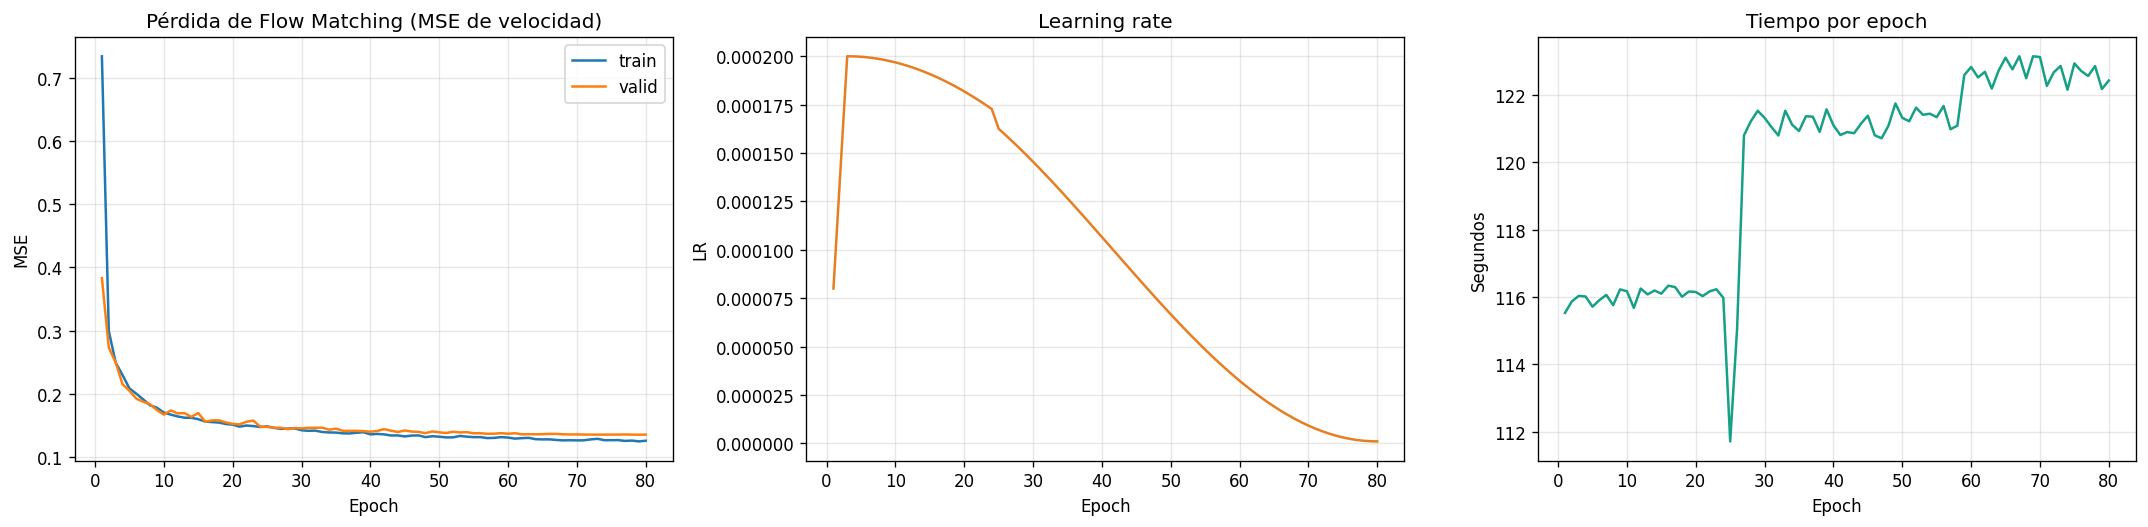

[INFO] Mejor val_loss: 0.13531 (epoch 79)


In [9]:
historial_df = pd.DataFrame(historial)

if len(historial_df) > 0:
    fig, axes = plt.subplots(1, 3, figsize=(18, 4.5), dpi=120)

    ax = axes[0]
    ax.plot(historial_df['epoch'], historial_df['train_loss'], label='train')
    ax.plot(historial_df['epoch'], historial_df['val_loss'], label='valid')
    ax.set_title('Pérdida de Flow Matching (MSE de velocidad)')
    ax.set_xlabel('Epoch'); ax.set_ylabel('MSE')
    ax.legend(); ax.grid(alpha=0.3)

    ax = axes[1]
    ax.plot(historial_df['epoch'], historial_df['lr'], color='#e67e22')
    ax.set_title('Learning rate')
    ax.set_xlabel('Epoch'); ax.set_ylabel('LR')
    ax.grid(alpha=0.3)

    ax = axes[2]
    ax.plot(historial_df['epoch'], historial_df['epoch_time_s'], color='#16a085')
    ax.set_title('Tiempo por epoch')
    ax.set_xlabel('Epoch'); ax.set_ylabel('Segundos')
    ax.grid(alpha=0.3)

    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / 'curvas_cfm.png', dpi=120, bbox_inches='tight')
    plt.show()

    print(f'[INFO] Mejor val_loss: {historial_df["val_loss"].min():.5f} '
          f'(epoch {int(historial_df.loc[historial_df["val_loss"].idxmin(), "epoch"])})')
else:
    print('[ADVERTENCIA] No hay historial para graficar.')

## 10. Generación de muestras

### ¿Qué se hace a continuación?
Se generan **80 muestras** (4 familias × 5 pitches `[36, 48, 60, 72, 84]` × 4 semillas) integrando la ODE con 50 pasos de Euler desde ruido nuevo. Se guardan en `muestras_cfm.npz` con la misma estructura que `muestras_generadas.npz` del NB03 y se muestra una grilla con la semilla 42.

### ¿Por qué se hace?
Se usan exactamente las mismas 20 condiciones y las mismas 4 semillas que en el NB03 para que la comparación con el VAE y con el baseline sea directa, condición por condición. Las 4 semillas por condición son las que permiten medir diversidad: con una sola muestra no se puede distinguir un generador que explora de uno que siempre devuelve lo mismo. El `.npz` es el insumo del torneo del NB05, donde el juez AST consume estos mels.

[INFO] Semilla 42: 20 muestras | rango=[-1.000, 1.000]
[INFO] Semilla 43: 20 muestras | rango=[-1.000, 1.000]
[INFO] Semilla 44: 20 muestras | rango=[-1.000, 1.000]
[INFO] Semilla 45: 20 muestras | rango=[-1.000, 1.000]
[INFO] Muestras generadas: (80, 1, 128, 128) | rango=[-1.000, 1.000] | finite=True
[INFO] Tiempo de muestreo: 9.2 s para 80 muestras (0.11 s/muestra con 50 pasos)
[INFO] Guardado: /kaggle/working/cfm_output/muestras_cfm.npz


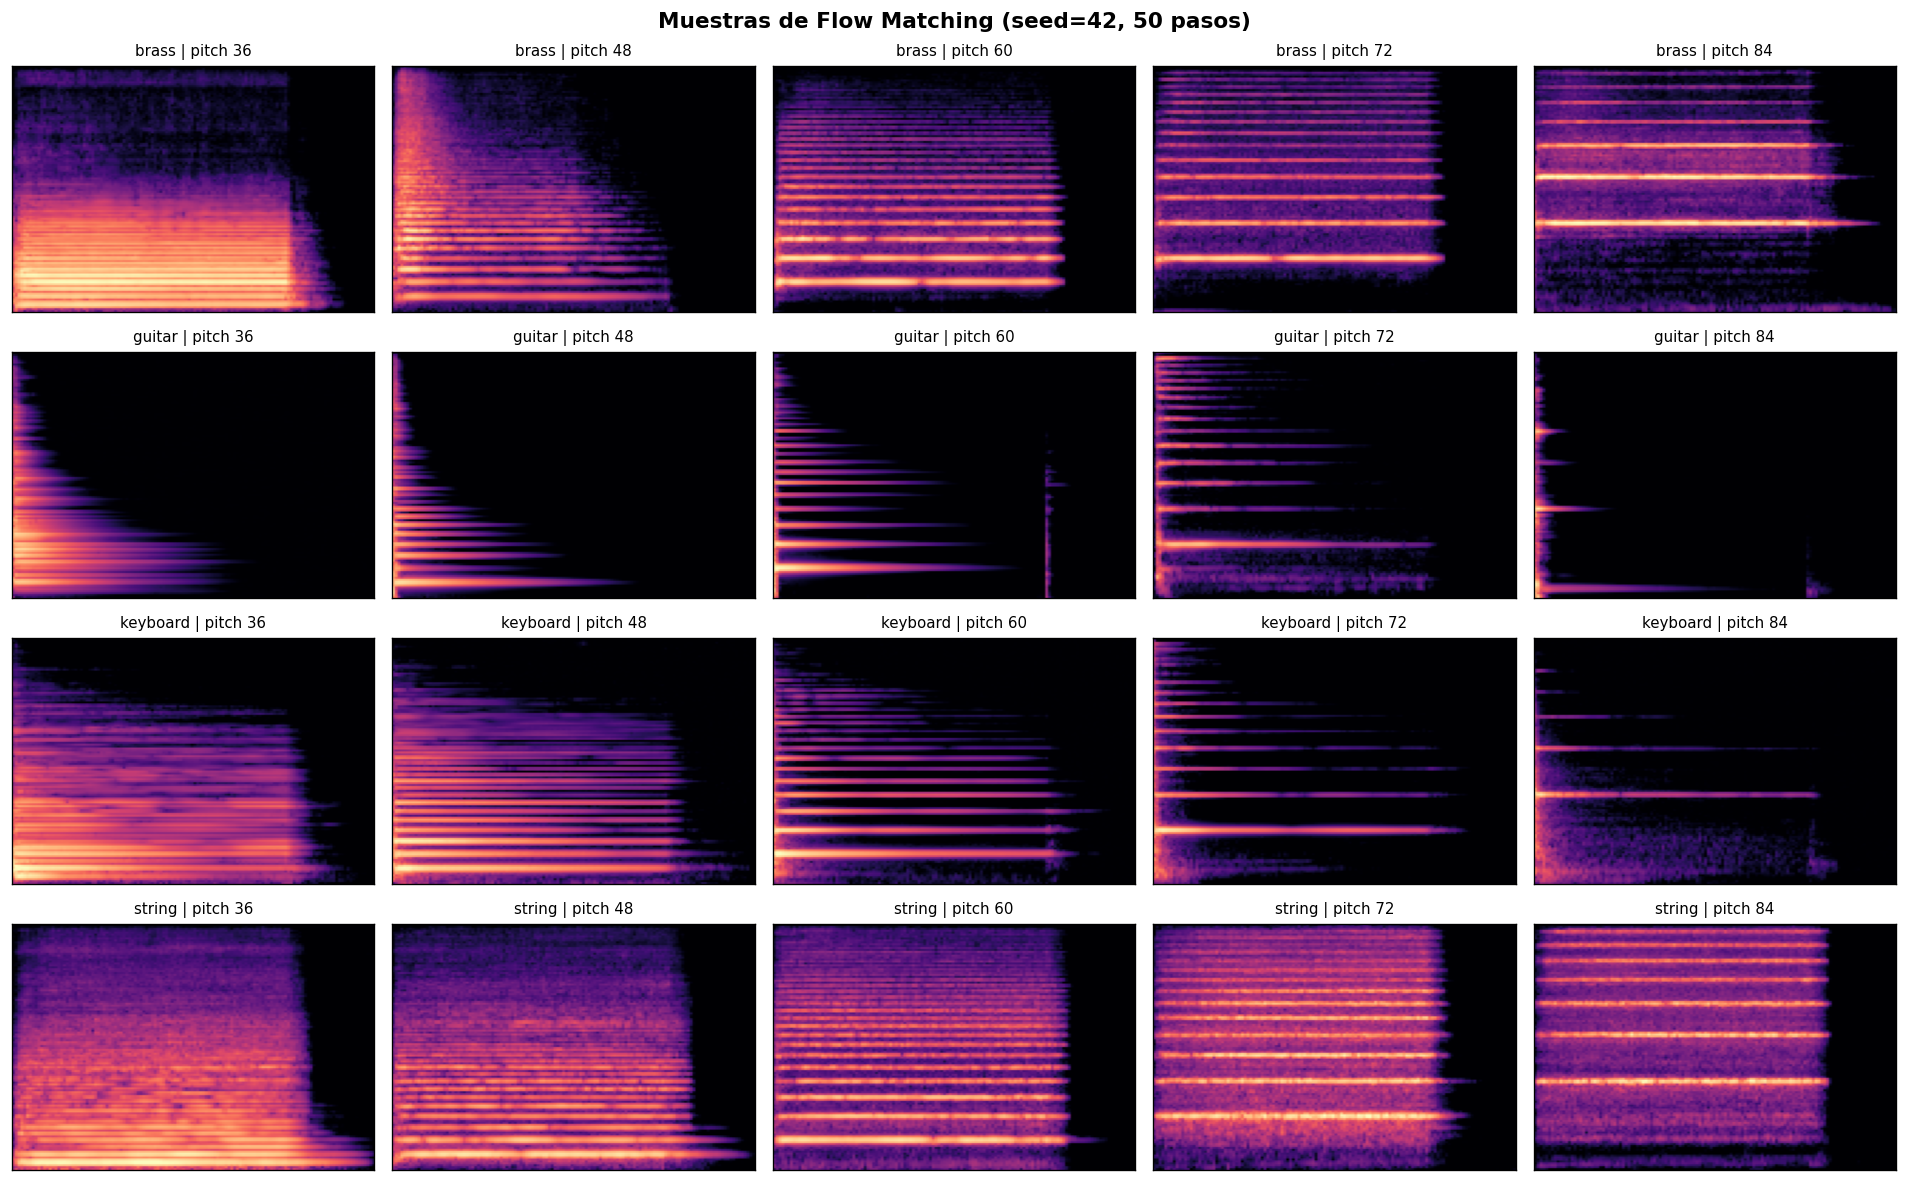

In [10]:
torch.manual_seed(SEED)

fam_gen, pit_gen, sem_gen = [], [], []
bloques = []
t0 = time.time()
for seed in GEN_SEEDS:
    fams = [f for f in range(NUM_FAMILIES) for _ in GEN_PITCHES]
    pits = [p for _ in range(NUM_FAMILIES) for p in GEN_PITCHES]
    mels_seed, _ = sample_cfm(
        model_eval, fams, pits, steps=EULER_STEPS, seed=seed, batch_size=10,
    )
    bloques.append(mels_seed)
    fam_gen.extend(fams)
    pit_gen.extend(pits)
    sem_gen.extend([seed] * len(fams))
    print(f'[INFO] Semilla {seed}: {len(mels_seed)} muestras | '
          f'rango=[{mels_seed.min():.3f}, {mels_seed.max():.3f}]')
gen_mels = torch.cat(bloques, 0)
t_gen = time.time() - t0

gen_f = torch.tensor(fam_gen, dtype=torch.long)
gen_p = torch.tensor(pit_gen, dtype=torch.long)
gen_seeds = torch.tensor(sem_gen, dtype=torch.long)

print(f'[INFO] Muestras generadas: {tuple(gen_mels.shape)} | '
      f'rango=[{gen_mels.min():.3f}, {gen_mels.max():.3f}] | '
      f'finite={torch.isfinite(gen_mels).all().item()}')
print(f'[INFO] Tiempo de muestreo: {t_gen:.1f} s para {len(gen_mels)} muestras '
      f'({t_gen/len(gen_mels):.2f} s/muestra con {EULER_STEPS} pasos)')
assert torch.isfinite(gen_mels).all().item()
assert len(gen_mels) == NUM_FAMILIES * len(GEN_PITCHES) * len(GEN_SEEDS)

np.savez_compressed(
    OUTPUT_DIR / 'muestras_cfm.npz',
    mels=gen_mels.numpy().astype(np.float32),
    families=gen_f.numpy().astype(np.int64),
    pitches=gen_p.numpy().astype(np.int64),
    seeds=gen_seeds.numpy().astype(np.int64),
    steps=np.int64(EULER_STEPS),
)
print(f'[INFO] Guardado: {OUTPUT_DIR / "muestras_cfm.npz"}')

mask = (gen_seeds == GEN_SEEDS[0])
fig, axes = plt.subplots(NUM_FAMILIES, len(GEN_PITCHES), figsize=(16, 10), dpi=120)
for r, f in enumerate(range(NUM_FAMILIES)):
    for c, p in enumerate(GEN_PITCHES):
        idx = ((gen_f == f) & (gen_p == p) & mask).nonzero(as_tuple=True)[0][0]
        ax = axes[r, c]
        ax.imshow(gen_mels[idx, 0].numpy(), origin='lower', aspect='auto',
                  cmap='magma', vmin=-1, vmax=1)
        ax.set_title(f'{FAMILY_NAMES[f]} | pitch {p}', fontsize=9)
        ax.set_xticks([]); ax.set_yticks([])
plt.suptitle(f'Muestras de Flow Matching (seed={GEN_SEEDS[0]}, {EULER_STEPS} pasos)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'muestras_cfm.png', dpi=120, bbox_inches='tight')
plt.show()

## 11. Métricas objetivas sin juez

### ¿Qué se hace a continuación?
Se calculan las mismas métricas del NB03 para poder comparar:

- **Error de pitch**: se vocodea cada muestra, se estima `f0` con `pyin` y se pasa a semitonos.
- **Diversidad**: diferencia L1 media por píxel entre pares de muestras de la misma condición.
- **FID-lite**: distancia de Fréchet sobre 14 features del mel (medias y desvíos por cuartiles, centroide, rolloff y energía).
- **Duración de la nota**: último frame que cae menos de 20 dB respecto del pico de la propia nota, en segundos, con la distribución completa por familia y el porcentaje de muestras que caen por debajo del p10 real de su familia ("atípicamente cortas").
- **Error de pitch robusto**: además de la media, la mediana, el porcentaje dentro de ±1 semitono y la media recortada sin errores de octava (> 6 st), porque unos pocos outliers de `pyin` arrastran la MAE.
- **Features del FID**: diferencia estandarizada de las 14 features entre generado y real, para ver qué término empuja la distancia.
- **Diversidad suavizada**: la misma diversidad L1 tras un suavizado 3×3, para separar estructura de grano de alta frecuencia.
- **Baseline de media**: el mel promedio de cada `(familia, pitch)` en `train`, como control inferior.

Si el notebook del NB03 está montado como dataset, se recalculan las métricas del VAE con **este mismo código**; si no, se usan los valores reportados por el NB03 y se aclara en la tabla.

### ¿Por qué se hace?
El pitch y la diversidad se miden sobre el audio generado, no sobre el mel, porque es la prueba más honesta: un mel puede parecer correcto y sonar desafinado. El FID-lite mide qué tan lejos está la distribución generada de la real, que es lo que el juez va a evaluar de forma indirecta. El baseline de media es el piso: si el generador no lo supera en FID y diversidad, no aporta nada. Ojo con la interpretación del pitch: la media condicional lo acierta por construcción, así que la ventaja del generador tiene que estar en FID y diversidad, no en el pitch.

La duración se mide respecto del pico de cada nota porque los mels se normalizaron con `power_to_db(ref=np.max)`: cada nota tiene su máximo en 0 dB y el piso en −80 dB, así que un umbral absoluto castigaría a las muestras generadas más débiles justo cuando la debilidad es parte del problema.

La duración se mide aparte porque **no está en la condición**: el modelo recibe familia y altura, pero cuánto dura la nota y cómo decae es una variable libre que muestrea. Eso explica que un mismo `(familia, pitch)` suene a nota sostenida en una semilla y a nota cortada en otra, y es la diferencia más audible que el FID-lite no captura: dos mels con la misma estructura armónica pero 3 s y 0,5 s de duración pueden dar features parecidas. Si la tasa de degeneradas es alta, el problema no es el vocoder ni el corte del archivo (todos los WAV duran exactamente 4 s): es el campo de velocidades entrando en una zona de silencio.

La forma de la distribución real importa para leer la tabla: en valid, brass es unimodal y sostenido (su p10 supera los 2 s), mientras que guitar, keyboard y string son **bimodales** —una fracción importante de sus notas decae por debajo de 1 s y el resto se sostiene más de 3 s—. O sea que un string de 0,4 s puede ser una nota legítima, pero un brass de 0,4 s no existe en los datos. Por eso el umbral es el p10 de cada familia y no uno global.

Dos precauciones de lectura. El FID-lite se mide contra las 80 notas reales emparejadas: es el mismo protocolo que el NB03, pero con 80 muestras el estimador de Fréchet tiene ruido, así que diferencias menores a ~0,03 no son concluyentes. Y la diversidad L1 por píxel crece con el grano de alta frecuencia además de con la variedad musical: por eso se reporta también la versión suavizada, que es la que hay que mirar para decidir si el modelo explora más que los datos.

Pitch CFM:   0%|          | 0/80 [00:00<?, ?it/s]

[INFO] Muestras del VAE encontradas en /kaggle/input/datasets/enzopalau/muestras-generadas/muestras_generadas.npz (80 muestras)


Pitch VAE:   0%|          | 0/80 [00:00<?, ?it/s]


[INFO] ===== MÉTRICAS OBJETIVAS (sin juez) =====
       modelo      fuente  comparable  diversidad_l1  diversidad_l1_suave  frechet_mel_lite  pitch_mae_st  pitch_medae_st  pct_dentro_1_st  pitch_mae_rec_st  pct_fuera_6_st
Flow Matching recalculado        True         0.2569               0.2467            0.2095        1.0575             0.1           0.9625            0.0799          0.0375
   VAE (NB03) recalculado        True         0.2250               0.2215            0.1231        0.7212             0.1           0.9625            0.1000          0.0250

[INFO] Pitch MAE: CFM=1.06 st | VAE=0.72 st
[INFO] Diversidad: CFM=0.2569 | VAE=0.2250
[INFO] FID-lite: CFM=0.21 | VAE=0.12

[INFO] Duración de la nota (último frame por encima de -20 dB):
 familia  real_p50_s  real_p10_s  gen_p50_s  gen_p10_s  gen_bajo_p10_%  vae_p50_s  vae_bajo_p10_%
   brass        3.09        2.50       3.09       2.95            10.0       3.06            25.0
  guitar        2.44        0.59       1.06  

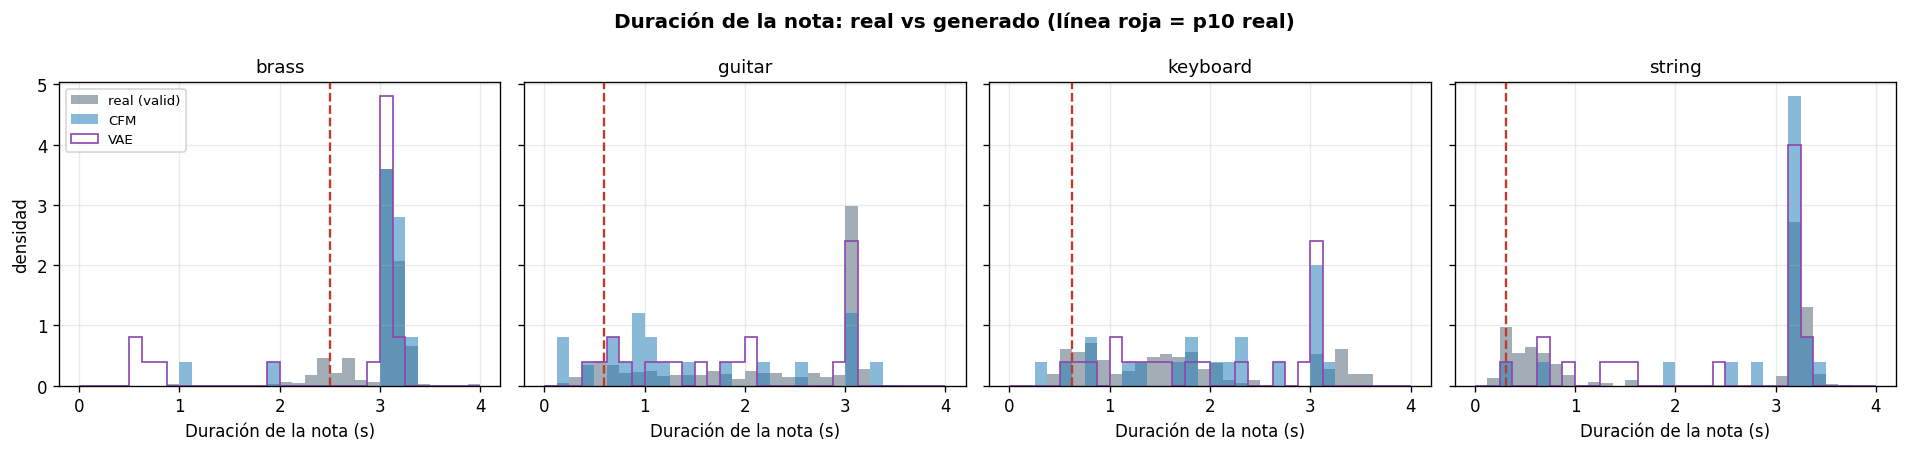

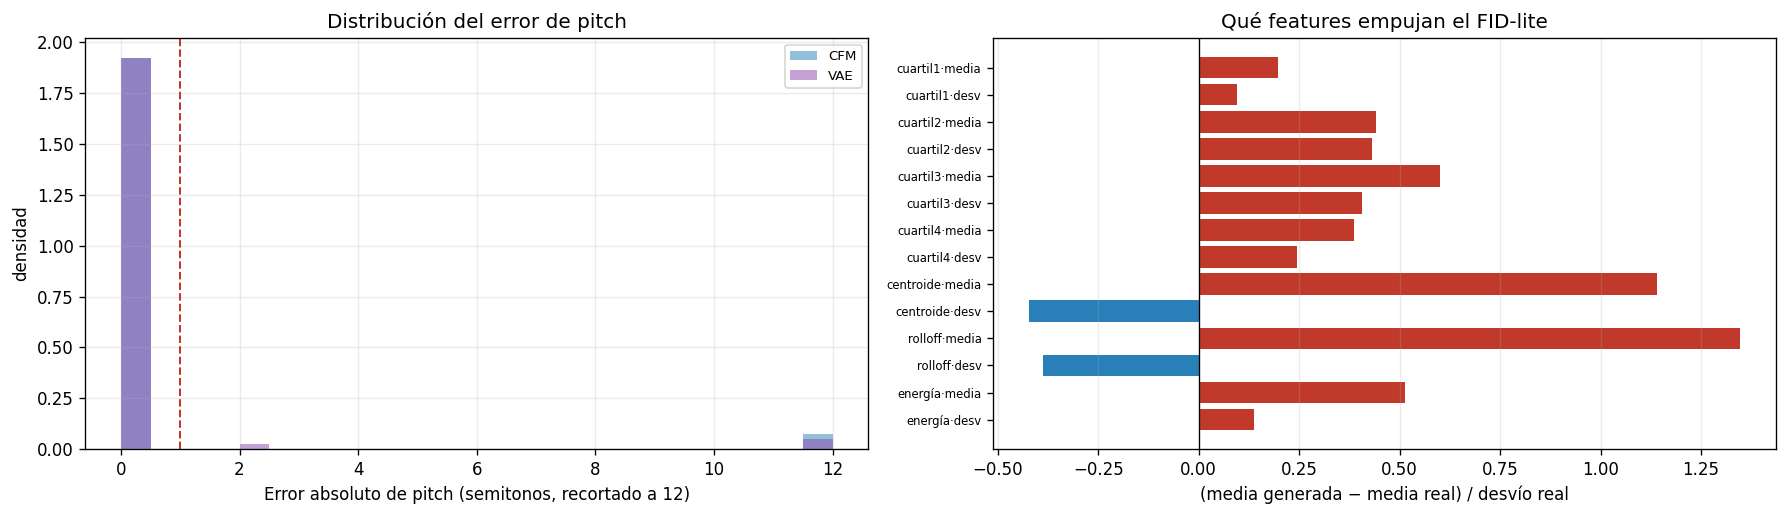

[INFO] Guardado: /kaggle/working/cfm_output/metricas_cfm.json


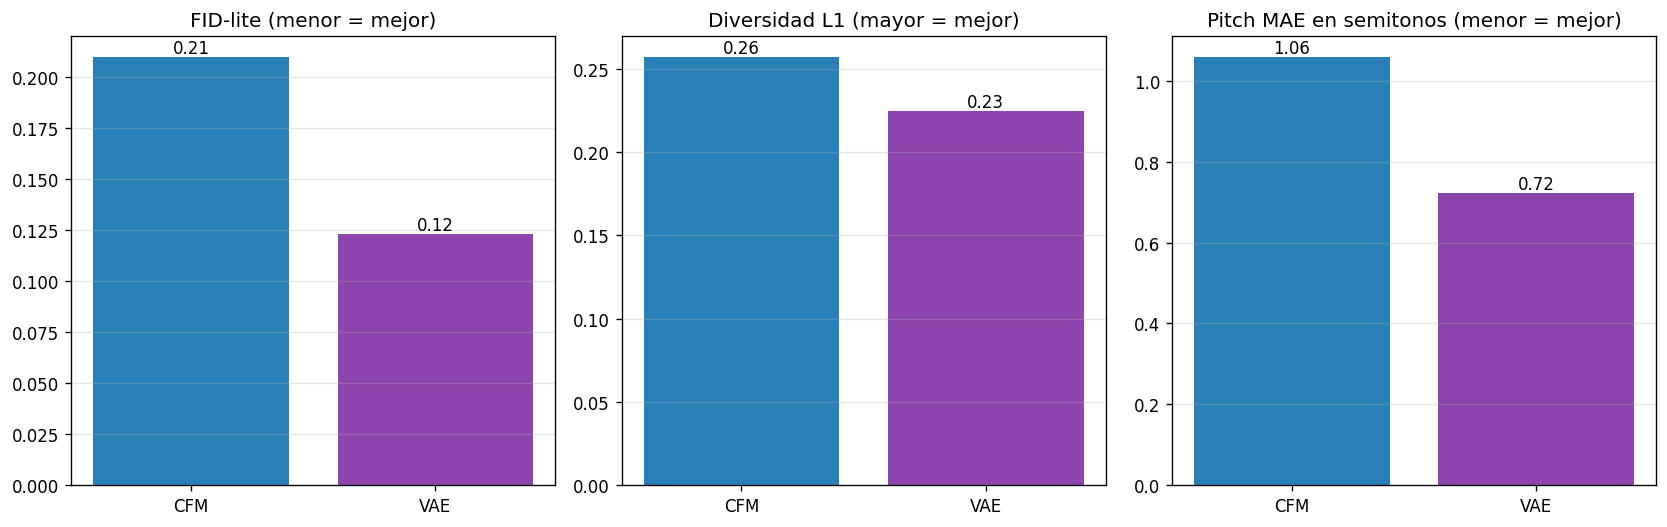

In [11]:
from scipy.linalg import sqrtm


def estimar_pitch_midi(wav, sr=SR):
    f0, voiced, _ = librosa.pyin(
        np.asarray(wav, dtype=np.float32),
        fmin=librosa.midi_to_hz(PITCH_MIN),
        fmax=librosa.midi_to_hz(PITCH_MAX + 6),
        sr=sr, frame_length=N_FFT, hop_length=HOP,
    )
    if f0 is None:
        return np.nan
    tiempos = librosa.times_like(f0, sr=sr, hop_length=HOP)
    mask = voiced & np.isfinite(f0) & (tiempos >= 0.15) & (tiempos <= 2.5)
    if mask.sum() == 0:
        mask = voiced & np.isfinite(f0)
    if mask.sum() == 0:
        return np.nan
    f_med = float(np.median(f0[mask]))
    return float(69.0 + 12.0 * np.log2(f_med / 440.0))


def diversidad_l1(mels):
    '''Diferencia absoluta media por píxel entre pares de muestras (0 a 2).'''
    if len(mels) < 2:
        return float('nan')
    flat = mels.flatten(1)
    d = torch.cdist(flat, flat, p=1)
    n = len(flat)
    return float(d.sum().item() / (n * (n - 1) * flat.shape[1]))


def features_mel(mels):
    x = mels[:, 0]
    feats = []
    for b in torch.chunk(x, 4, dim=1):
        feats.append(b.mean(dim=(1, 2)))
        feats.append(b.std(dim=(1, 2)))
    freqs = torch.linspace(0, 1, x.shape[1]).view(1, x.shape[1], 1)
    energy = (x + 1.0).clamp(min=0)
    total = energy.sum(dim=1) + 1e-8
    centroid = (energy * freqs).sum(dim=1) / total
    feats.append(centroid.mean(dim=1))
    feats.append(centroid.std(dim=1))
    cum = torch.cumsum(energy, dim=1)
    thr = 0.85 * cum[:, -1:, :]
    rolloff = (cum < thr).sum(dim=1).float() / x.shape[1]
    feats.append(rolloff.mean(dim=1))
    feats.append(rolloff.std(dim=1))
    feats.append(energy.mean(dim=(1, 2)))
    feats.append(energy.std(dim=(1, 2)))
    return torch.stack(feats, dim=1).numpy()


def frechet_distance(a, b):
    mu1, mu2 = a.mean(0), b.mean(0)
    C1 = np.cov(a, rowvar=False) + 1e-6 * np.eye(a.shape[1])
    C2 = np.cov(b, rowvar=False) + 1e-6 * np.eye(b.shape[1])
    covmean = sqrtm(C1 @ C2)
    if np.iscomplexobj(covmean):
        covmean = covmean.real
    return float(np.sum((mu1 - mu2) ** 2) + np.trace(C1 + C2 - 2 * covmean))


# ── Condiciones y referencia real emparejada ───────────────────────────────
condiciones = sorted(set(zip(gen_f.tolist(), gen_p.tolist())))

def real_emparejado(f, p, i=0):
    idx = ((y_val == f) & (p_val == p)).nonzero(as_tuple=True)[0]
    if len(idx) == 0:
        idx_f = (y_val == f).nonzero(as_tuple=True)[0]
        idx = idx_f[(p_val[idx_f] - p).abs().argmin()].view(1)
    return X_val[idx[min(i, len(idx) - 1)]]

matched = torch.stack([real_emparejado(f, p) for f, p in zip(gen_f.tolist(), gen_p.tolist())])
f_real = features_mel(matched)


errores_pitch = {}


def metricas_de(mels, fams, pits, etiqueta, con_pitch=True):
    '''Diversidad, FID-lite y (opcionalmente) pitch para un conjunto de mels.'''
    mels = mels.float()
    divs = [diversidad_l1(mels[(fams == f) & (pits == p)]) for f, p in condiciones]
    div = float(np.nanmean(divs))
    # La diversidad L1 por píxel también sube con el grano de alta frecuencia.
    # Se repite la medición tras un suavizado 3×3 para separar estructura de ruido.
    mels_suave = F.avg_pool2d(mels, 3, stride=1, padding=1)
    divs_suave = [diversidad_l1(mels_suave[(fams == f) & (pits == p)]) for f, p in condiciones]
    div_suave = float(np.nanmean(divs_suave))
    fd = frechet_distance(features_mel(mels), f_real)
    out = {
        'n_muestras': int(len(mels)),
        'diversidad_l1': div,
        'diversidad_l1_suave': div_suave,
        'frechet_mel_lite': fd,
    }
    if con_pitch:
        errs = []
        for i in tqdm(range(len(mels)), desc=f'Pitch {etiqueta}', leave=False):
            wav = vocoder.mel_norm_to_audio(mels[i, 0].numpy(), n_iter=64)
            errs.append(abs(estimar_pitch_midi(wav) - float(pits[i])))
        errs = np.asarray(errs, dtype=np.float64)
        errores_pitch[etiqueta] = errs
        validos = errs[np.isfinite(errs)]
        rec = validos[validos <= 6.0]  # sin errores de octava de pyin
        out.update({
            'pitch_mae_st': float(np.nanmean(errs)),
            'pitch_medae_st': float(np.nanmedian(errs)),
            'pct_dentro_1_st': float(np.nanmean(errs <= 1.0)),
            'pitch_mae_rec_st': float(rec.mean()) if len(rec) else float('nan'),
            'pct_fuera_6_st': float(np.mean(validos > 6.0)) if len(validos) else float('nan'),
        })
    return out


metricas_cfm = metricas_de(gen_mels, gen_f, gen_p, 'CFM')

# ── VAE de referencia ──────────────────────────────────────────────────────
# Kaggle descomprime los .npz al subirlos (son zips), así que el artefacto
# puede llegar como carpeta con los .npy adentro en vez de como archivo.
def cargar_npz(ruta):
    '''Carga un .npz, venga como archivo o como carpeta descomprimida.'''
    ruta = Path(ruta)
    if ruta.is_file():
        return np.load(ruta)

    class _NpzDescomprimido(dict):
        @property
        def files(self):
            return list(self.keys())

    datos = _NpzDescomprimido()
    for f in sorted(ruta.glob('*.npy')):
        datos[f.stem] = np.load(f)
    if 'mels' not in datos:
        raise FileNotFoundError(
            f'{ruta} no parece un .npz descomprimido: no tiene mels.npy')
    print(f'[INFO] {ruta.name}/: .npz descomprimido por Kaggle '
          f'({", ".join(datos.files)})')
    return datos


vae_mels = None
candidatos_vae = [
    Path('/kaggle/input/datasets/enzopalau/muestras-generadas/muestras_generadas.npz'),
    Path('/kaggle/input/muestras-generadas/muestras_generadas.npz'),
]
# Respaldo: buscar solo archivos .npz o carpetas que realmente tengan .npy adentro
candidatos_vae += [
    p
    for raiz in (Path('/kaggle/input'), Path('.'))
    if raiz.exists()
    for p in sorted(raiz.rglob('*'))
    if ''.join(ch for ch in p.name.lower() if ch.isalnum())
    in ('muestrasgeneradas', 'muestrasgeneradasnpz')
    and (p.is_file() or any(p.glob('*.npy')))
]
# El dataset renombra la carpeta con guiones ('muestras-generadas') y Kaggle
# descomprime el .npz, así que se busca también por nombre normalizado.
candidatos_vae += [
    p
    for raiz in (OUTPUT_DIR.parent, Path('.'), Path('/kaggle/input'))
    if raiz.exists()
    for p in sorted(raiz.rglob('*'))
    if ''.join(ch for ch in p.name.lower() if ch.isalnum())
    in ('muestrasgeneradas', 'muestrasgeneradasnpz')
]
for ruta_vae in candidatos_vae:
    if ruta_vae.exists():
        datos_vae = cargar_npz(ruta_vae)
        vae_mels = torch.from_numpy(datos_vae['mels'].astype(np.float32))
        vae_f = torch.from_numpy(datos_vae['families'].astype(np.int64))
        vae_p = torch.from_numpy(datos_vae['pitches'].astype(np.int64))
        print(f'[INFO] Muestras del VAE encontradas en {ruta_vae} ({len(vae_mels)} muestras)')
        break

if vae_mels is not None and 'seeds' not in datos_vae.files:
    print('[ADVERTENCIA] muestras_generadas.npz no tiene semillas; sin eso no se '
          'puede alinear con las del CFM. Se usan los valores del NB03.')
    vae_mels = None

if vae_mels is not None:
    # alinear por (semilla, familia, pitch) para que el FID sea comparable
    vae_seeds = torch.from_numpy(datos_vae['seeds'].astype(np.int64))
    claves_vae = {
        (int(s), int(f), int(p)): i
        for i, (s, f, p) in enumerate(zip(vae_seeds, vae_f, vae_p))
    }
    claves_cfm = list(zip(gen_seeds.tolist(), gen_f.tolist(), gen_p.tolist()))
    faltantes = [k for k in claves_cfm if k not in claves_vae]
    if faltantes:
        print(f'[ADVERTENCIA] {len(faltantes)} muestras del VAE no coinciden en '
              f'(semilla, familia, pitch). Se usan los valores del NB03.')
        vae_mels = None

if vae_mels is not None:
    idx_vae = [claves_vae[k] for k in claves_cfm]
    vae_mels_ord = vae_mels[idx_vae]
    metricas_vae = metricas_de(vae_mels_ord, gen_f, gen_p, 'VAE')
    fuente_vae = 'recalculado'
else:
    # Valores tal como se reportaron en el NB03. Se completan las columnas que
    # ese notebook no medía con NaN en vez de dejar la celda vacía, para que se
    # vea que faltan y no que valen cero.
    metricas_vae = {
        'n_muestras': 80,
        'diversidad_l1': 0.2299,
        'diversidad_l1_suave': float('nan'),
        'frechet_mel_lite': 0.12,
        'pitch_mae_st': 1.24,
        'pitch_medae_st': float('nan'),
        'pct_dentro_1_st': 0.938,
        'pitch_mae_rec_st': float('nan'),
        'pct_fuera_6_st': float('nan'),
    }
    fuente_vae = 'NB03'
    print('[INFO] No se encontró muestras_generadas.npz del NB03; '
          'se usan los valores reportados en ese notebook.')

# ── Tabla comparativa ──────────────────────────────────────────────────────
# La columna fuente deja explícito si cada fila se recalculó con este mismo
# código o si viene de los valores reportados en el NB03: sin eso, comparar
# pitch y FID entre modelos no es estricto.
vae_comparable = (fuente_vae == 'recalculado')
df_metricas = pd.DataFrame([
    {'modelo': 'Flow Matching', 'fuente': 'recalculado', 'comparable': True,
     **{k: v for k, v in metricas_cfm.items() if k != 'n_muestras'}},
    {'modelo': 'VAE (NB03)', 'fuente': fuente_vae, 'comparable': vae_comparable,
     **{k: v for k, v in metricas_vae.items() if k != 'n_muestras'}},
])
print('\n[INFO] ===== MÉTRICAS OBJETIVAS (sin juez) =====')
print(df_metricas.round(4).to_string(index=False))

# Sin el npz, la fila del VAE viene de otro código: otro conjunto de
# referencia para el FID y otro umbral para la duración. Ponerla al lado del
# CFM invita a leer una mejora que no está medida.
sufijo_vae = '' if vae_comparable else ' (NB03, NO comparable)'
if not vae_comparable:
    print('\n[ADVERTENCIA] La fila del VAE NO es comparable: son los valores del NB03, '
          'donde el FID-lite se calculó con otro conjunto de referencia y la duración '
          'con otro umbral. Montá vae_output/muestras_generadas.npz como input para '
          'recalcularla con este mismo código (con SOLO_EVALUAR=True alcanza).')

print(f'\n[INFO] Pitch MAE: CFM={metricas_cfm["pitch_mae_st"]:.2f} st | '
      f'VAE={metricas_vae["pitch_mae_st"]:.2f} st{sufijo_vae}')
print(f'[INFO] Diversidad: CFM={metricas_cfm["diversidad_l1"]:.4f} | '
      f'VAE={metricas_vae["diversidad_l1"]:.4f}{sufijo_vae}')
print(f'[INFO] FID-lite: CFM={metricas_cfm["frechet_mel_lite"]:.2f} | '
      f'VAE={metricas_vae["frechet_mel_lite"]:.2f}{sufijo_vae}')


# ── Duración de la nota: lo que el FID-lite no ve ─────────────────────────
def fin_de_nota(mel, caida_db=20.0):
    '''Último frame que está a menos de `caida_db` del pico de la propia nota.

    `mel` viene normalizado en [-1, 1] con (dB + 40) / 40, así que multiplicar
    por 40 y restar 40 devuelve dB. Los mels se construyeron con
    `power_to_db(ref=np.max)`: cada nota tiene su pico en 0 dB y el piso en
    -80 dB. Por eso el umbral es relativo al pico y no absoluto: una muestra
    generada puede no llegar a 0 dB, y con un umbral absoluto se subestimaría
    su duración justo en las muestras más débiles, que son las que hay que
    diagnosticar.
    '''
    perfil = np.asarray(mel).max(axis=0) * 40.0 - 40.0
    pico = float(perfil.max())
    if not np.isfinite(pico) or pico < -60.0:
        return 0  # mel sin energía: no hay nota
    activo = np.where(perfil > pico - caida_db)[0]
    return int(activo[-1] + 1) if len(activo) else 0


def duracion_s(frames):
    return frames * HOP / SR


fin_gen = np.array([fin_de_nota(m) for m in gen_mels[:, 0].numpy()])
fin_real = np.array([fin_de_nota(m) for m in matched[:, 0].numpy()])
fam_ord = gen_f.numpy()

# Referencia de duración: TODO valid de cada familia, no las 80 emparejadas.
# Con 170-827 notas por familia el p10 es un umbral estable; con 20, no.
fin_valid = np.array([fin_de_nota(m) for m in X_val[:, 0].numpy()])
fam_valid = y_val.numpy()
p10_por_familia = {
    f: float(np.percentile(fin_valid[fam_valid == f], 10)) for f in range(NUM_FAMILIES)
}

# Una muestra es "atípicamente corta" si su nota dura menos que el 10% más corto
# de las notas reales de su familia. El criterio es relativo a propósito: un piano
# que decae rápido es normal, un brass de 0,6 s no existe en los datos.
corta_gen = np.array([fin_gen[k] < p10_por_familia[int(fam_ord[k])]
                      for k in range(len(fin_gen))])
corta_real = np.array([fin_real[k] < p10_por_familia[int(fam_ord[k])]
                       for k in range(len(fin_real))])

fin_vae = None
if vae_mels is not None:
    fin_vae = np.array([fin_de_nota(m) for m in vae_mels_ord[:, 0].numpy()])
    corta_vae = np.array([fin_vae[k] < p10_por_familia[int(fam_ord[k])]
                          for k in range(len(fin_vae))])

filas_dur = []
for f in range(NUM_FAMILIES):
    sel = fam_ord == f
    sel_v = fam_valid == f
    fila = {
        'familia': FAMILY_NAMES[f],
        'real_p50_s': float(np.median(fin_valid[sel_v])) * HOP / SR,
        'real_p10_s': p10_por_familia[f] * HOP / SR,
        'gen_p50_s': float(np.median(fin_gen[sel])) * HOP / SR,
        'gen_p10_s': float(np.percentile(fin_gen[sel], 10)) * HOP / SR,
        'gen_bajo_p10_%': float(corta_gen[sel].mean() * 100),
    }
    if fin_vae is not None:
        fila['vae_p50_s'] = float(np.median(fin_vae[sel])) * HOP / SR
        fila['vae_bajo_p10_%'] = float(corta_vae[sel].mean() * 100)
    filas_dur.append(fila)
df_dur = pd.DataFrame(filas_dur)
pct_gen_corta = float(corta_gen.mean() * 100)
pct_real_corta = float(corta_real.mean() * 100)
print('\n[INFO] Duración de la nota (último frame por encima de -20 dB):')
print(df_dur.round(2).to_string(index=False))
print(f'[INFO] Notas más cortas que el p10 de su familia: CFM {pct_gen_corta:.1f}% '
      f'({int(corta_gen.sum())}/{len(corta_gen)}) | real emparejado {pct_real_corta:.1f}%'
      + (f' | VAE {float(corta_vae.mean() * 100):.1f}%' if fin_vae is not None else ''))

# ── Distribución de duraciones: la distribución completa, no un ejemplo ─────
fig, axes = plt.subplots(1, NUM_FAMILIES, figsize=(16, 3.8), dpi=120, sharey=True)
bins = np.linspace(0, 4.0, 33)
for f, ax in enumerate(axes):
    ax.hist(fin_valid[fam_valid == f] * HOP / SR, bins=bins, density=True,
            alpha=0.45, color='#34495e', label='real (valid)')
    ax.hist(fin_gen[fam_ord == f] * HOP / SR, bins=bins, density=True,
            alpha=0.55, color='#2980b9', label='CFM')
    if fin_vae is not None:
        ax.hist(fin_vae[fam_ord == f] * HOP / SR, bins=bins, density=True,
                histtype='step', lw=1.8, color='#8e44ad', label='VAE')
    ax.axvline(p10_por_familia[f] * HOP / SR, color='#c0392b', ls='--', lw=1.4)
    ax.set_title(FAMILY_NAMES[f], fontsize=11)
    ax.set_xlabel('Duración de la nota (s)')
    ax.grid(alpha=0.25)
axes[0].set_ylabel('densidad')
axes[0].legend(fontsize=8)
plt.suptitle('Duración de la nota: real vs generado (línea roja = p10 real)',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'duraciones.png', dpi=120, bbox_inches='tight')
plt.show()

# ── Error de pitch y features que empujan el FID-lite ──────────────────────
nombres_feat = []
for q in range(4):
    nombres_feat += [f'cuartil{q+1}·media', f'cuartil{q+1}·desv']
nombres_feat += ['centroide·media', 'centroide·desv', 'rolloff·media', 'rolloff·desv',
                 'energía·media', 'energía·desv']
f_gen_feat = features_mel(gen_mels)
z_feat = (f_gen_feat.mean(0) - f_real.mean(0)) / (f_real.std(0) + 1e-8)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.4), dpi=120)

ax = axes[0]
for etq, col in [('CFM', '#2980b9'), ('VAE', '#8e44ad')]:
    if etq in errores_pitch:
        e = errores_pitch[etq]
        e = e[np.isfinite(e)]
        ax.hist(np.clip(e, 0, 12), bins=np.arange(0, 12.5, 0.5), density=True,
                alpha=0.5, color=col, label=etq)
ax.axvline(1.0, color='#c0392b', ls='--', lw=1.2)
ax.set_xlabel('Error absoluto de pitch (semitonos, recortado a 12)')
ax.set_ylabel('densidad')
ax.set_title('Distribución del error de pitch')
ax.legend(fontsize=8)
ax.grid(alpha=0.25)

ax = axes[1]
ax.barh(np.arange(len(z_feat)), z_feat,
        color=['#c0392b' if v > 0 else '#2980b9' for v in z_feat])
ax.set_yticks(np.arange(len(z_feat)))
ax.set_yticklabels(nombres_feat, fontsize=7)
ax.invert_yaxis()  # cuartil 1 arriba, energía abajo
ax.axvline(0, color='k', lw=0.8)
ax.set_xlabel('(media generada − media real) / desvío real')
ax.set_title('Qué features empujan el FID-lite')
ax.grid(alpha=0.25, axis='x')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'diagnostico_features.png', dpi=120, bbox_inches='tight')
plt.show()

metricas = {
    'cfm': metricas_cfm,
    'vae': {**metricas_vae, 'fuente': fuente_vae},
    'duracion_nota': df_dur.round(3).to_dict(orient='records'),
    'notas_cortas': {
        'cfm_pct': pct_gen_corta,
        'real_pct': pct_real_corta,
        **({'vae_pct': float(corta_vae.mean() * 100)} if fin_vae is not None else {}),
    },
    'features_z': dict(zip(nombres_feat, [float(v) for v in z_feat])),
    'real_matched': {'diversidad_l1': float(np.nanmean([
        diversidad_l1(X_val[((y_val == f) & (p_val == p)).nonzero(as_tuple=True)[0][:4]])
        for f, p in condiciones
        if ((y_val == f) & (p_val == p)).sum() >= 2
    ]))},
    'config': config_actual,
    'euler_steps': EULER_STEPS,
    'usar_ema': bool(USAR_EMA),
    'data_mean': DATA_MEAN,
    'data_std': DATA_STD,
}
with open(OUTPUT_DIR / 'metricas_cfm.json', 'w', encoding='utf-8') as fh:
    json.dump(to_py(metricas), fh, indent=2, ensure_ascii=False)
print(f'[INFO] Guardado: {OUTPUT_DIR / "metricas_cfm.json"}')

# ── Gráfico comparativo ────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5), dpi=120)
colores = ['#2980b9', '#8e44ad']
for ax, (col, titulo) in zip(axes, [
    ('frechet_mel_lite', 'FID-lite (menor = mejor)'),
    ('diversidad_l1', 'Diversidad L1 (mayor = mejor)'),
    ('pitch_mae_st', 'Pitch MAE en semitonos (menor = mejor)'),
]):
    etiquetas = ['CFM', 'VAE']
    vals = [metricas_cfm[col], metricas_vae[col]]
    barras = ax.bar(etiquetas, vals, color=colores)
    if not vae_comparable:
        # Barra rayada: el número del VAE viene del NB03, no de este código.
        barras[1].set_hatch('//')
        barras[1].set_edgecolor('white')
        etiquetas[1] = 'VAE (NB03)'
        ax.set_xticks(range(2))
        ax.set_xticklabels(etiquetas, fontsize=9)
    ax.set_title(titulo)
    ax.grid(alpha=0.3, axis='y')
    for i, v in enumerate(vals):
        txt = f'{v:.2f}' if np.isfinite(v) else 's/d'
        ax.text(i, v if np.isfinite(v) else 0.0, txt, ha='center', va='bottom',
                fontsize=10)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'comparativa_metricas.png', dpi=120, bbox_inches='tight')
plt.show()

## 12. ¿Cuántos pasos de integración hacen falta?

### ¿Qué se hace a continuación?
Se generan las **mismas 80 muestras de la sección 11** (20 condiciones × 4 semillas) con 10, 25, 50 y 100 pasos de Euler, y se mide FID-lite, diversidad y tiempo por muestra para cada configuración. Usar las mismas condiciones y la misma referencia real que la tabla principal hace que los FID de esta sección sean comparables con los de allá; con 16 muestras el estimador de Fréchet es demasiado inestable.

### ¿Por qué se hace?
La promesa de Flow Matching es generar en pocos pasos. Este experimento lo verifica sobre el modelo real y no sobre la teoría: si con 10 pasos el FID es casi el mismo que con 100, se puede usar el modelo barato en el torneo; si hay una diferencia grande, conviene pagar los 50. También sirve para el informe: es una curva de compromiso calidad/costo medida, no citada.

[INFO]  10 pasos: FID-lite=0.227 | div=0.1893 | nota p50=2.77 s | bajo p10=11.2% | 2.2 s (0.03 s/muestra)
[INFO]  25 pasos: FID-lite=0.209 | div=0.2347 | nota p50=2.83 s | bajo p10=12.5% | 4.6 s (0.06 s/muestra)
[INFO]  50 pasos: FID-lite=0.211 | div=0.2629 | nota p50=2.78 s | bajo p10=15.0% | 9.3 s (0.12 s/muestra)
[INFO] 100 pasos: FID-lite=0.219 | div=0.2760 | nota p50=3.03 s | bajo p10=13.8% | 18.7 s (0.23 s/muestra)

[INFO] Compromiso calidad/costo:
 steps   fid  diversidad  nota_p50_s  bajo_p10_%  tiempo_s  s_por_muestra
    10 0.227       0.189       2.766       11.25     2.204          0.028
    25 0.209       0.235       2.828       12.50     4.629          0.058
    50 0.211       0.263       2.781       15.00     9.290          0.116
   100 0.219       0.276       3.031       13.75    18.722          0.234


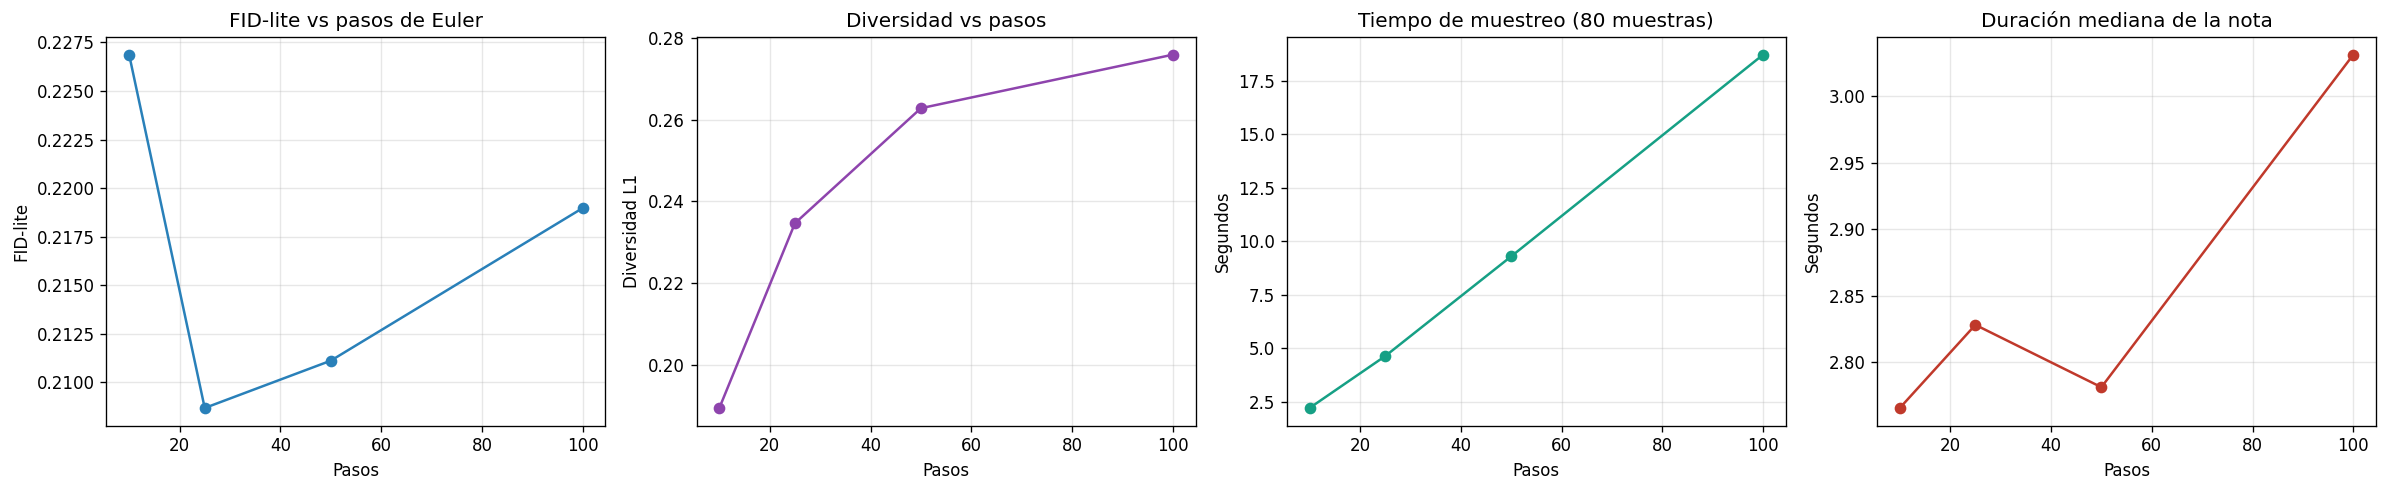

In [12]:
# Las mismas 80 condiciones de la sección 11 (no un subconjunto en pitch 60):
# así el FID-lite de esta tabla es comparable con el de la tabla principal.
fams_steps = gen_f.tolist()
pits_steps = gen_p.tolist()
fams_steps_t = torch.tensor(fams_steps, dtype=torch.long)
pits_steps_t = torch.tensor(pits_steps, dtype=torch.long)

cond_steps = sorted(set(zip(fams_steps, pits_steps)))
matched_steps = torch.stack([real_emparejado(f, p) for f, p in zip(fams_steps, pits_steps)])
f_real_steps = features_mel(matched_steps)

filas_pasos = []
for steps in (10, 25, 50, 100):
    t0 = time.time()
    mels_s, _ = sample_cfm(
        model_eval, fams_steps, pits_steps, steps=steps, seed=123, batch_size=8,
    )
    dt = time.time() - t0
    div = float(np.nanmean([
        diversidad_l1(mels_s[(fams_steps_t == f) & (pits_steps_t == p)])
        for f, p in cond_steps
    ]))
    fd = frechet_distance(features_mel(mels_s), f_real_steps)
    fines_s = np.array([fin_de_nota(m) for m in mels_s[:, 0].numpy()])
    umbral_s = np.array([p10_por_familia[f] for f in fams_steps])
    fila = {'steps': steps, 'fid': fd, 'diversidad': div,
            'nota_p50_s': float(np.median(fines_s)) * HOP / SR,
            'bajo_p10_%': float((fines_s < umbral_s).mean() * 100),
            'tiempo_s': dt, 's_por_muestra': dt / len(mels_s)}
    filas_pasos.append(fila)
    print(f'[INFO] {steps:3d} pasos: FID-lite={fd:.3f} | div={div:.4f} | '
          f'nota p50={fila["nota_p50_s"]:.2f} s | bajo p10={fila["bajo_p10_%"]:.1f}% | '
          f'{dt:.1f} s ({dt/len(mels_s):.2f} s/muestra)')

df_pasos = pd.DataFrame(filas_pasos)
print('\n[INFO] Compromiso calidad/costo:')
print(df_pasos.round(3).to_string(index=False))

fig, axes = plt.subplots(1, 4, figsize=(20, 4.2), dpi=120)
axes[0].plot(df_pasos['steps'], df_pasos['fid'], marker='o', color='#2980b9')
axes[0].set_title('FID-lite vs pasos de Euler')
axes[0].set_xlabel('Pasos'); axes[0].set_ylabel('FID-lite'); axes[0].grid(alpha=0.3)
axes[1].plot(df_pasos['steps'], df_pasos['diversidad'], marker='o', color='#8e44ad')
axes[1].set_title('Diversidad vs pasos')
axes[1].set_xlabel('Pasos'); axes[1].set_ylabel('Diversidad L1'); axes[1].grid(alpha=0.3)
axes[2].plot(df_pasos['steps'], df_pasos['tiempo_s'], marker='o', color='#16a085')
axes[2].set_title('Tiempo de muestreo (80 muestras)')
axes[2].set_xlabel('Pasos'); axes[2].set_ylabel('Segundos'); axes[2].grid(alpha=0.3)
axes[3].plot(df_pasos['steps'], df_pasos['nota_p50_s'], marker='o', color='#c0392b')
axes[3].set_title('Duración mediana de la nota')
axes[3].set_xlabel('Pasos'); axes[3].set_ylabel('Segundos'); axes[3].grid(alpha=0.3)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'pasos_vs_calidad.png', dpi=120, bbox_inches='tight')
plt.show()

df_pasos.to_csv(OUTPUT_DIR / 'pasos_vs_calidad.csv', index=False)
metricas['pasos'] = df_pasos.to_dict(orient='records')
with open(OUTPUT_DIR / 'metricas_cfm.json', 'w', encoding='utf-8') as fh:
    json.dump(to_py(metricas), fh, indent=2, ensure_ascii=False)

## 13. Comparación visual real vs generado

### ¿Qué se hace a continuación?
Para cada familia, en el pitch más cercano a 70, se muestra el mel real de `valid`, la muestra generada por el CFM y el mapa de diferencia. Esos mismos mels son los que se escuchan en la sección siguiente.

La nota real que se muestra es la de **duración mediana** entre las de esa condición (no la primera al azar), para que la comparación no dependa de haber sacado una nota atípicamente larga o corta. Del lado generado se generan 4 candidatas por familia y se eligen las 2 cuya duración está más cerca de la real, porque la duración es una variable libre que el modelo muestrea: una candidata degenerada (la nota muere antes de 1 s) no representa al modelo, pero tampoco se esconde, porque la tasa se cuantifica en la sección 11 y se imprime abajo junto a las 4 duraciones.

### ¿Por qué se hace?
Las métricas agregadas esconden cosas: un FID bajo puede convivir con muestras que pierden el ataque o que inventan armónicos. Mirar el par real/generado y la diferencia muestra dónde acierta el modelo (posición de los armónicos, envolvente general) y dónde falla (dinámica de la nota, ruido de fondo). Es la misma condición que se usa para escuchar, así que lo que se ve y lo que se oye coinciden.

[INFO] brass    p70 (15 reales): real 3.06 s | candidatas [3.0, 3.06, 3.12, 3.09] s | se muestran 3.06 y 3.09 s
[INFO] guitar   p70 (17 reales): real 1.00 s | candidatas [1.25, 1.19, 0.81, 1.41] s | se muestran 1.19 y 0.81 s
[INFO] keyboard p70 (4 reales): real 1.62 s | candidatas [1.19, 0.97, 0.84, 0.62] s | se muestran 1.19 y 0.97 s
[INFO] string   p70 (8 reales): real 0.34 s | candidatas [3.19, 3.22, 3.12, 3.03] s | se muestran 3.03 y 3.12 s


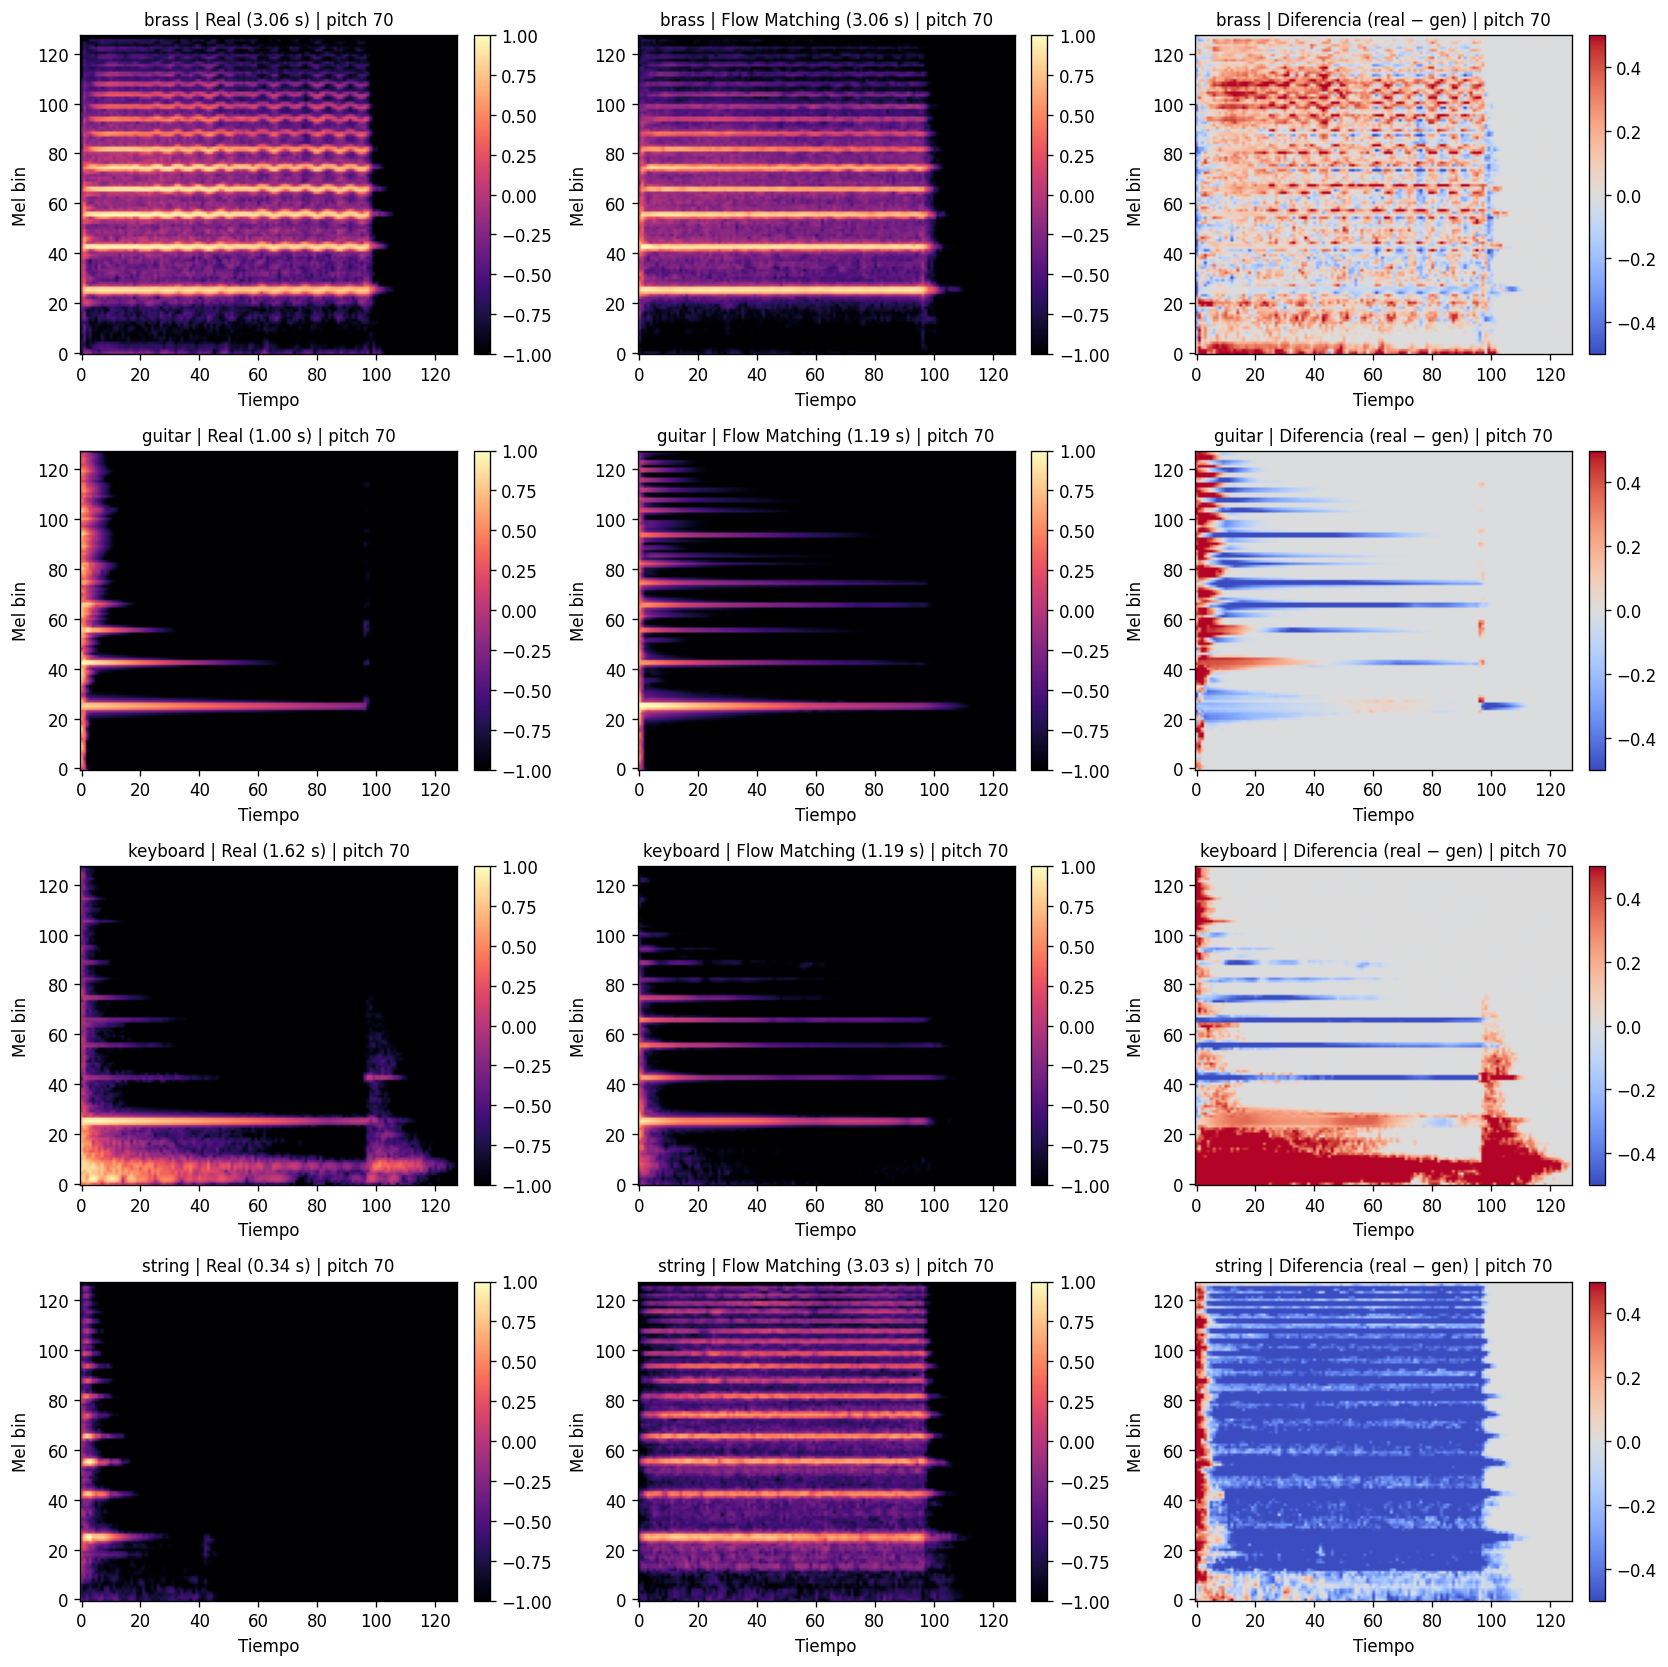

In [13]:
N_CANDIDATAS = 4
escucha = []
for f in range(NUM_FAMILIES):
    idx_f = (y_val == f).nonzero(as_tuple=True)[0]
    p_use = int(p_val[idx_f][(p_val[idx_f] - LISTEN_PITCH).abs().argmin()].item())
    idx = idx_f[p_val[idx_f] == p_use]
    # Nota real de duración mediana de la condición (no la primera al azar).
    fines_reales = np.array([fin_de_nota(X_val[j, 0].numpy()) for j in idx.tolist()])
    i = idx[int(np.argmin(np.abs(fines_reales - np.median(fines_reales))))].item()
    real_mel = X_val[i, 0].numpy()

    gen_m, _ = sample_cfm(model_eval, [f] * N_CANDIDATAS, [p_use] * N_CANDIDATAS,
                          steps=EULER_STEPS, seed=100 + f, batch_size=N_CANDIDATAS)
    cand = [gen_m[k, 0].numpy() for k in range(N_CANDIDATAS)]
    fines = [fin_de_nota(m) for m in cand]
    fin_real = fin_de_nota(real_mel)
    orden = np.argsort([abs(v - fin_real) for v in fines])
    escucha.append({
        'family': f, 'pitch': p_use, 'real': real_mel,
        'gen_a': cand[orden[0]], 'gen_b': cand[orden[1]],
        'fin_real': fin_real, 'fin_a': fines[orden[0]], 'fin_b': fines[orden[1]],
    })
    print(f"[INFO] {FAMILY_NAMES[f]:8s} p{p_use} ({len(idx)} reales): real {duracion_s(fin_real):.2f} s | "
          f"candidatas {[round(duracion_s(v), 2) for v in fines]} s | "
          f"se muestran {duracion_s(fines[orden[0]]):.2f} y {duracion_s(fines[orden[1]]):.2f} s")

fig, axes = plt.subplots(NUM_FAMILIES, 3, figsize=(14, 14), dpi=120)
for row, ej in enumerate(escucha):
    diff = ej['real'] - ej['gen_a']
    paneles = [
        (ej['real'], f"Real ({duracion_s(ej['fin_real']):.2f} s)", 'magma', -1, 1),
        (ej['gen_a'], f"Flow Matching ({duracion_s(ej['fin_a']):.2f} s)", 'magma', -1, 1),
        (diff, 'Diferencia (real − gen)', 'coolwarm', -0.5, 0.5),
    ]
    for col, (data, titulo, cmap, vmin, vmax) in enumerate(paneles):
        ax = axes[row, col]
        im = ax.imshow(data, origin='lower', aspect='auto', cmap=cmap, vmin=vmin, vmax=vmax)
        ax.set_title(f'{FAMILY_NAMES[ej["family"]]} | {titulo} | pitch {ej["pitch"]}', fontsize=10)
        ax.set_xlabel('Tiempo'); ax.set_ylabel('Mel bin')
        plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'real_vs_cfm.png', dpi=120, bbox_inches='tight')
plt.show()

## 14. Trayectorias de la ODE

### ¿Qué se hace a continuación?
Se genera una muestra (brass, pitch 60) guardando el estado `x_t` en `t = 0, 0.24, 0.50, 0.74, 1.0` y se grafican los cinco mels junto con su media y desvío.

### ¿Por qué se hace?
Es la forma más directa de ver qué aprendió el modelo: cómo el ruido blanco se convierte, paso a paso, en una estructura armónica. Si la estructura aparece recién al final, el integrador está haciendo casi todo el trabajo en los últimos pasos y conviene revisar el entrenamiento; si aparece de forma gradual, el campo de velocidades está bien aprendido. Además sirve como figura didáctica para el informe.

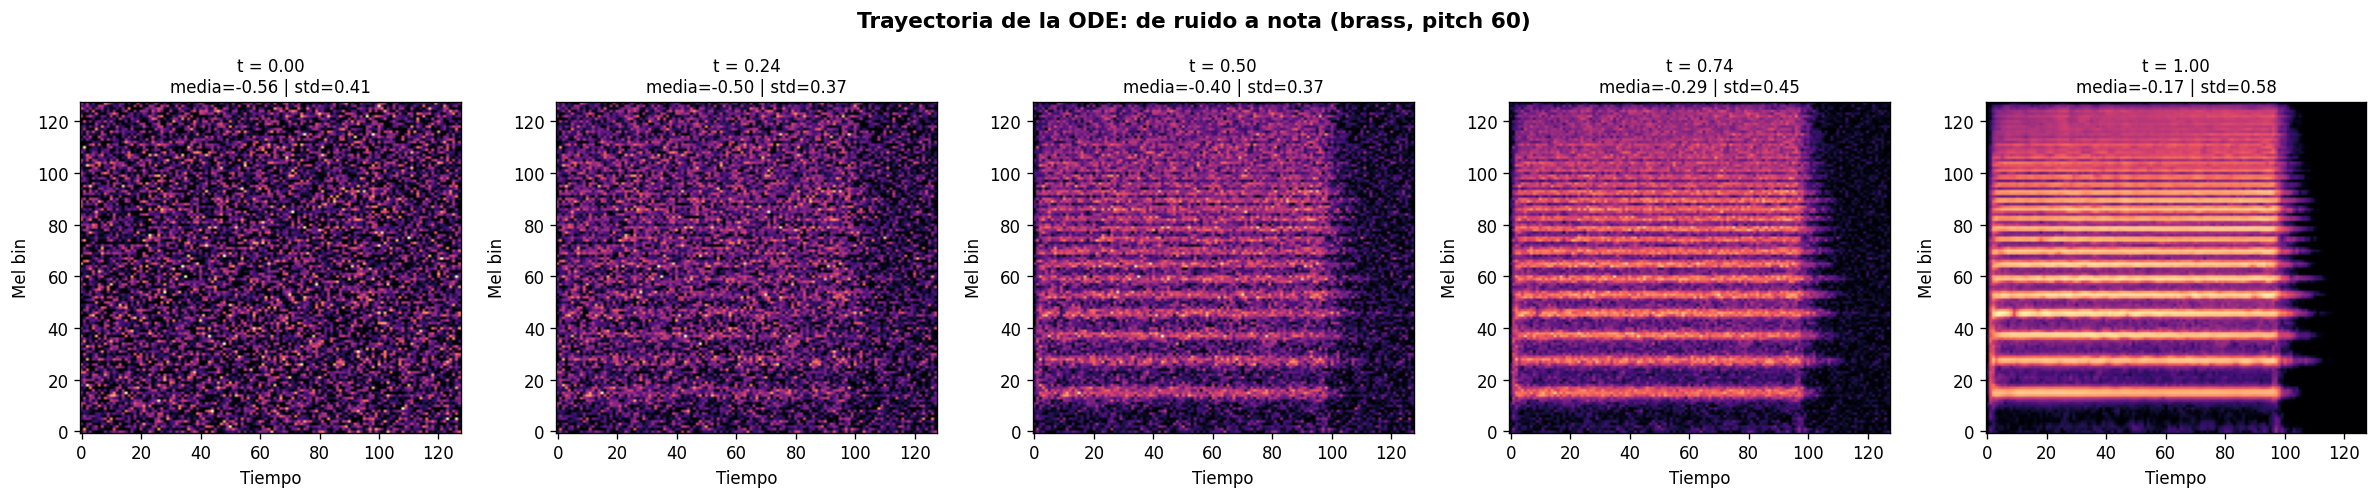

In [14]:
PASOS_TRAY = 50
record = [0, 12, 25, 37, PASOS_TRAY]
_, tray = sample_cfm(
    model_eval, [0], [60], steps=PASOS_TRAY, seed=7, batch_size=1, record_steps=record,
)

fig, axes = plt.subplots(1, len(record), figsize=(4 * len(record), 4.2), dpi=120)
for ax, k in zip(axes, record):
    img = tray[k][0, 0].numpy()
    ax.imshow(img, origin='lower', aspect='auto', cmap='magma', vmin=-1, vmax=1)
    ax.set_title(f't = {k/PASOS_TRAY:.2f}\nmedia={img.mean():.2f} | std={img.std():.2f}', fontsize=10)
    ax.set_xlabel('Tiempo'); ax.set_ylabel('Mel bin')
plt.suptitle('Trayectoria de la ODE: de ruido a nota (brass, pitch 60)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'trayectorias.png', dpi=120, bbox_inches='tight')
plt.show()

## 15. Ejemplos de escucha

### ¿Qué se hace a continuación?
Para cada familia, en el pitch más cercano a 70, se sintetizan con Griffin-Lim el mel real y dos muestras del CFM de la misma semilla (las dos candidatas más típicas en duración), se guardan como WAV `PCM_16` de 4 s y se reproducen dentro del notebook. Junto a cada una se imprime la duración de la nota. También se arma un ZIP con los 12 audios.

### ¿Por qué se hace?
Es la prueba que ninguna métrica reemplaza. El vocoder es el mismo del NB03 (ya corregido: sin pre-énfasis, sin doble normalización, con compuerta suave y fade), así que las diferencias que se escuchen son del modelo y no del post-procesado. Comparar dos muestras de la misma condición también muestra si el modelo explora o repite, y las duraciones impresas explican por qué una nota puede sonar "cortada": el archivo siempre dura 4 s, lo que cambia es dónde el modelo decidió que terminaba la nota.

In [15]:
for p in AUDIO_DIR.glob('*.wav'):
    p.unlink()

for ej in escucha:
    nombre = FAMILY_NAMES[ej['family']]
    p_use = ej['pitch']
    wav_real = vocoder.mel_norm_to_audio(ej['real'], n_iter=250)
    wav_ga = vocoder.mel_norm_to_audio(ej['gen_a'], n_iter=250)
    wav_gb = vocoder.mel_norm_to_audio(ej['gen_b'], n_iter=250)

    sf.write(AUDIO_DIR / f'real_{nombre}_p{p_use}.wav', wav_real, SR, subtype='PCM_16')
    sf.write(AUDIO_DIR / f'cfm_{nombre}_p{p_use}_a.wav', wav_ga, SR, subtype='PCM_16')
    sf.write(AUDIO_DIR / f'cfm_{nombre}_p{p_use}_b.wav', wav_gb, SR, subtype='PCM_16')

    semilla = 100 + ej['family']
    print(f'\n--- {nombre.upper()} | pitch {p_use} | nota real {duracion_s(ej["fin_real"]):.2f} s ---')
    print('1) Real (mel real -> Griffin-Lim):')
    ipd.display(ipd.Audio(wav_real, rate=SR))
    print(f'2) Flow Matching (semilla {semilla}, muestra 1 | nota {duracion_s(ej["fin_a"]):.2f} s):')
    ipd.display(ipd.Audio(wav_ga, rate=SR))
    print(f'3) Flow Matching (semilla {semilla}, muestra 2 | nota {duracion_s(ej["fin_b"]):.2f} s):')
    ipd.display(ipd.Audio(wav_gb, rate=SR))

with zipfile.ZipFile(OUTPUT_DIR / 'audio_cfm.zip', 'w', zipfile.ZIP_DEFLATED) as z:
    for p in sorted(AUDIO_DIR.glob('*.wav')):
        z.write(p, arcname=p.name)
print(f'\n[INFO] ZIP de audios: {OUTPUT_DIR / "audio_cfm.zip"}')


--- BRASS | pitch 70 | nota real 3.06 s ---
1) Real (mel real -> Griffin-Lim):


2) Flow Matching (semilla 100, muestra 1 | nota 3.06 s):


3) Flow Matching (semilla 100, muestra 2 | nota 3.09 s):



--- GUITAR | pitch 70 | nota real 1.00 s ---
1) Real (mel real -> Griffin-Lim):


2) Flow Matching (semilla 101, muestra 1 | nota 1.19 s):


3) Flow Matching (semilla 101, muestra 2 | nota 0.81 s):


... (3 outputs left out)


--- STRING | pitch 70 | nota real 0.34 s ---
1) Real (mel real -> Griffin-Lim):


2) Flow Matching (semilla 103, muestra 1 | nota 3.03 s):


3) Flow Matching (semilla 103, muestra 2 | nota 3.12 s):



[INFO] ZIP de audios: /kaggle/working/cfm_output/audio_cfm.zip


## 16. Resumen y próximos pasos

### ¿Qué se hace a continuación?
Se imprime el resumen del notebook (épocas, mejor val, métricas, archivos generados) y se listan los pasos que siguen.

### ¿Por qué se hace?
Deja cerrado el hito con los números a mano para el informe y para el torneo. Los archivos que importan son `muestras_cfm.npz` (entrada del NB05) y `cfm_best.pt` (modelo entrenado).

In [16]:
archivos = sorted(OUTPUT_DIR.glob('*'))
print('[INFO] ===== RESUMEN NB04 =====')
print(f'  Arquitectura          : CondCFMUNet ({n_params/1e6:.2f} M parámetros)')
print(f'  Épocas entrenadas     : {len(historial["epoch"])}/{EPOCHS}')
print(f'  Mejor val_loss        : {min(historial["val_loss"]):.5f}')
print(f'  Pesos usados          : {"EMA" if USAR_EMA else "crudos"}')
print(f'  Pasos de Euler        : {EULER_STEPS}')
print(f'  Pitch MAE CFM         : {metricas_cfm["pitch_mae_st"]:.2f} semitonos')
print(f'  Pitch dentro de ±1 st : {metricas_cfm["pct_dentro_1_st"]*100:.1f}%')
print(f'  Diversidad CFM        : {metricas_cfm["diversidad_l1"]:.4f} '
      f'(suavizada {metricas_cfm["diversidad_l1_suave"]:.4f})')
print(f'  Diversidad real       : {metricas["real_matched"]["diversidad_l1"]:.4f}')
print(f'  FID-lite CFM          : {metricas_cfm["frechet_mel_lite"]:.2f}')
print(f'  FID-lite VAE          : {metricas_vae["frechet_mel_lite"]:.2f}{sufijo_vae}')
print(f'  Duración nota (p50)   : CFM {df_dur["gen_p50_s"].mean():.2f} s | '
      f'real {df_dur["real_p50_s"].mean():.2f} s')
print(f'  Notas bajo el p10     : CFM {pct_gen_corta:.1f}% | real {pct_real_corta:.1f}%')
print()
print('[INFO] Archivos generados:')
for p in archivos:
    if p.is_file():
        print(f'  {p.name:32s} {p.stat().st_size/1024:10.1f} KB')
print()
print('[INFO] Próximo paso:')
print('  1. Revisar curvas, muestras, trayectorias y audios.')
print('  2. Descargar cfm_output/ (o Quick Save en Kaggle).')
print('  3. Llevar muestras_cfm.npz al NB05 (torneo con el juez AST)')
print('     y comparar VAE vs Flow Matching.')

with open(OUTPUT_DIR / 'resumen_cfm.txt', 'w', encoding='utf-8') as fh:
    fh.write('NB04 Flow Matching\n')
    fh.write(f'epocas={len(historial["epoch"])}/{EPOCHS}\n')
    fh.write(f'mejor_val={min(historial["val_loss"]):.6f}\n')
    fh.write(f'pesos={"EMA" if USAR_EMA else "crudos"}\n')
    fh.write(f'pitch_mae={metricas_cfm["pitch_mae_st"]:.4f}\n')
    fh.write(f'diversidad={metricas_cfm["diversidad_l1"]:.4f}\n')
    fh.write(f'fid_lite={metricas_cfm["frechet_mel_lite"]:.4f}\n')
print(f'[INFO] Resumen: {OUTPUT_DIR / "resumen_cfm.txt"}')

[INFO] ===== RESUMEN NB04 =====
  Arquitectura          : CondCFMUNet (7.20 M parámetros)
  Épocas entrenadas     : 80/80
  Mejor val_loss        : 0.13531
  Pesos usados          : crudos
  Pasos de Euler        : 50
  Pitch MAE CFM         : 1.06 semitonos
  Pitch dentro de ±1 st : 96.2%
  Diversidad CFM        : 0.2569 (suavizada 0.2467)
  Diversidad real       : 0.2424
  FID-lite CFM          : 0.21
  FID-lite VAE          : 0.12
  Duración nota (p50)   : CFM 2.36 s | real 2.55 s
  Notas bajo el p10     : CFM 8.8% | real 10.0%

[INFO] Archivos generados:
  audio_cfm.zip                         900.9 KB
  cfm_best.pt                        112797.9 KB
  cfm_last.pt                        112798.0 KB
  comparativa_metricas.png               43.8 KB
  curvas_cfm.png                        100.0 KB
  diagnostico_features.png               68.3 KB
  duraciones.png                         39.5 KB
  historial_cfm.csv                       7.0 KB
  metricas_cfm.json                       3